In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h2o
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
import mlflow.h2o
import mlflow

import config

#import warnings
#warnings.filterwarnings('ignore')

In [2]:
# define Mlflow env. settings
mlflow.set_tracking_uri(uri=config.mlflow_uri)
%env MLFLOW_TRACKING_URI= config.mlflow_db
%env mlflow_tracking_username = config.mlflow_un
%env mlflow_tracking_password = config.mlflow_pw

# Initialize H2O server
h2o.init(ip="127.0.0.1", port="8080", nthreads=-1, min_mem_size= config.min_memory, max_mem_size= config.max_memory, enable_assertions=False)

# Clear h2o memory
h2o.remove_all()

env: MLFLOW_TRACKING_URI=config.mlflow_db
env: mlflow_tracking_username=config.mlflow_un
env: mlflow_tracking_password=config.mlflow_pw
Checking whether there is an H2O instance running at http://127.0.0.1:8080..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.411-b09, mixed mode)
  Starting server from C:\DSE\Python\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\RANDLE~1.KNI\AppData\Local\Temp\4\tmp8cm7mpl_
  JVM stdout: C:\Users\RANDLE~1.KNI\AppData\Local\Temp\4\tmp8cm7mpl_\h2o_randle_knight_started_from_python.out
  JVM stderr: C:\Users\RANDLE~1.KNI\AppData\Local\Temp\4\tmp8cm7mpl_\h2o_randle_knight_started_from_python.err
  Server is running at http://127.0.0.1:8080
Connecting to H2O server at http://127.0.0.1:8080 ... successful.


H2O_cluster_uptime:,03 secs
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.3
H2O_cluster_version_age:,29 days
H2O_cluster_name:,H2O_from_python_randle_knight_d9zm4q
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,112.3 Gb
H2O_cluster_total_cores:,16
H2O_cluster_allowed_cores:,16
H2O_cluster_status:,"locked, healthy"


In [3]:
customerList = ["X5","X7"] #,"X3","X4","X1","X2","X6"] # "X5","X7","X8"

#Replace with dynamic code later Not full list of audit types
# Full list
#FilterTypeList = ['AddTest','Aliquot','Authorize','CalculationUpdate','Cancel','CancelResult','CancelSample','CancelTest','CreateQCSample','EditTests','FileImport','ModifyBaseDate','ModifySample','Prepare','ReactivateSample','ReceiveSample','Reject','ReleaseSample','RemoveTest','ReSample','RestoreResult','RestoreSample','RestoreTest','ReviewAuditTrail','Reviewed','TableUpdate','UnReceiveSample','UpdateBatch','UpdateLot'] 
# Non-problematic list
FilterTypeList = ['AddTest','Aliquot','Authorize','CalculationUpdate','CancelSample','CancelTest','EditTests','FileImport','ModifySample','ReactivateSample','ReceiveSample','UnReceiveSample']  
# Testing
#FilterTypeList = ['AddTest']


#Details: ERRR on field: sample_size: Parameter sample_size must be in interval [2, 100000] but it is 256'
#x5 ['CancelResult','ModifyBaseDate','Prepare','Reject','ReSample','RemoveTest','ReviewAuditTrail','Reviewed','UpdateBatch'] 
#x7 ['Cancel','CreateQCSample','ReleaseSample''RestoreResult','RestoreSample','TableUpdate','UpdateLot']
#x8 ['RestoreSample'] 
#mlflow.autolog()

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, OPTIONAL_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, SIGNED_JSON, RELEASED_JSON, OPTIONAL_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, USES_CODES_JSON, ALLOW_CANCEL_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


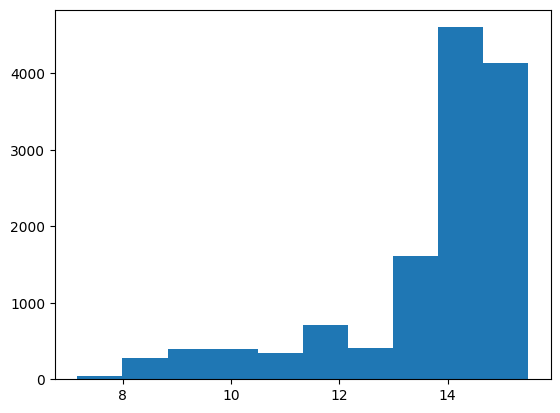

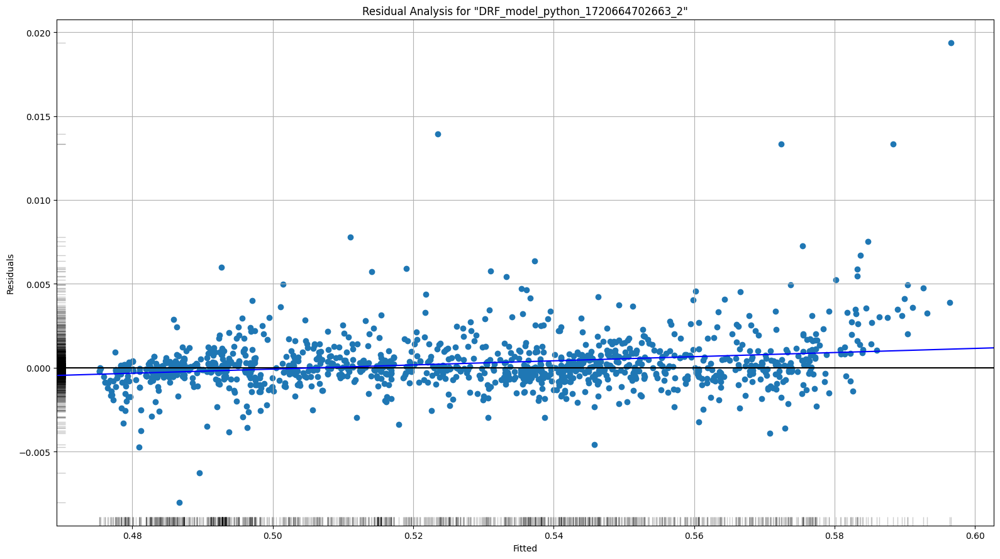

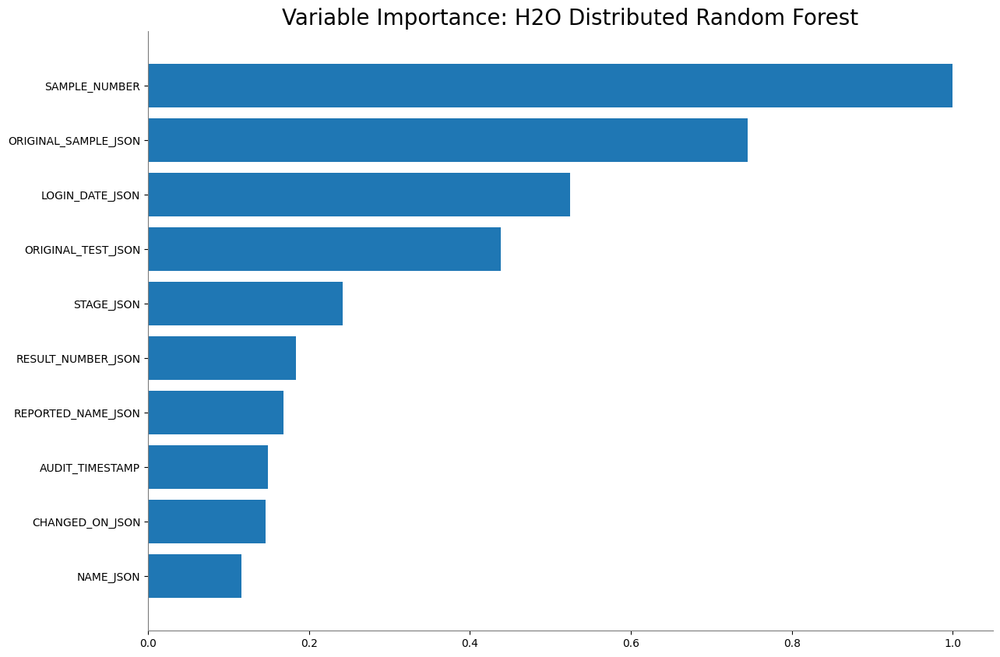

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PREP_JSON, RELEASED_JSON, OPTIONAL_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, DISPLAYED_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, OPTIONAL_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

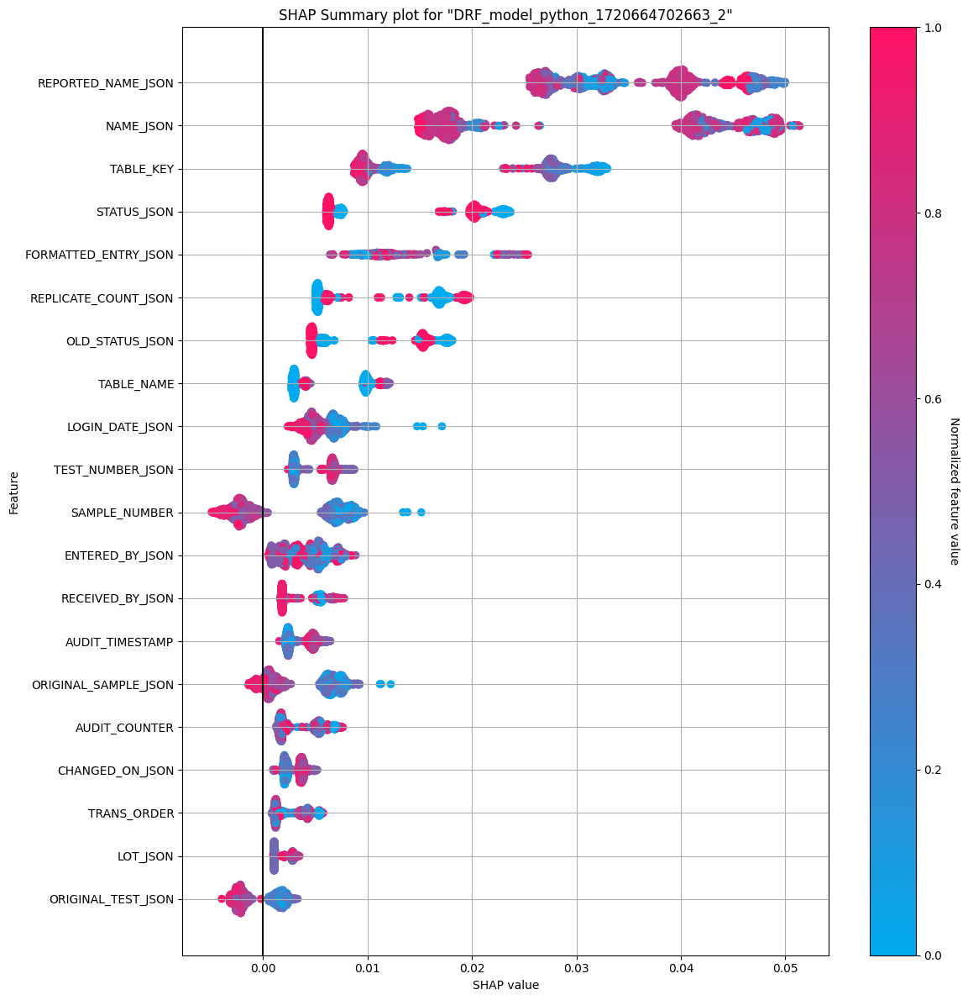

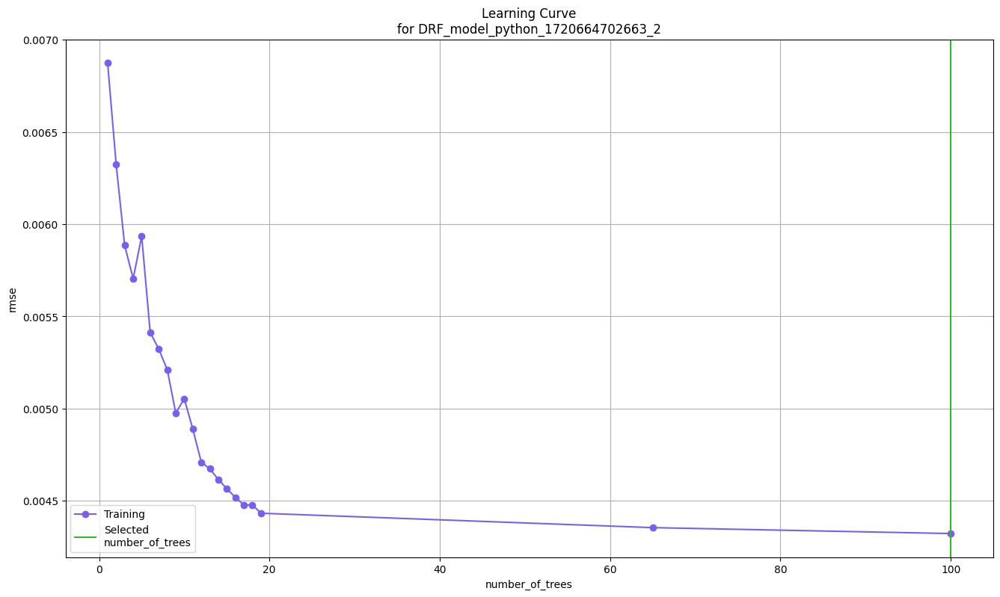

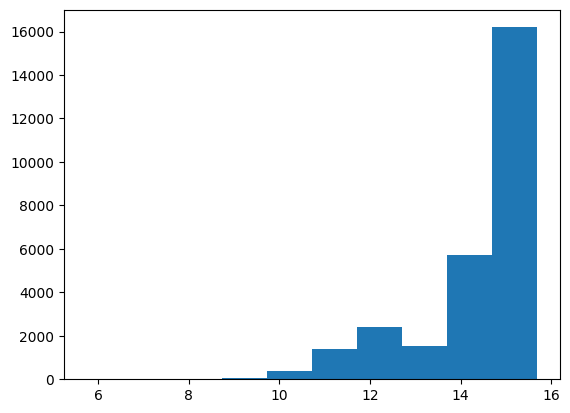

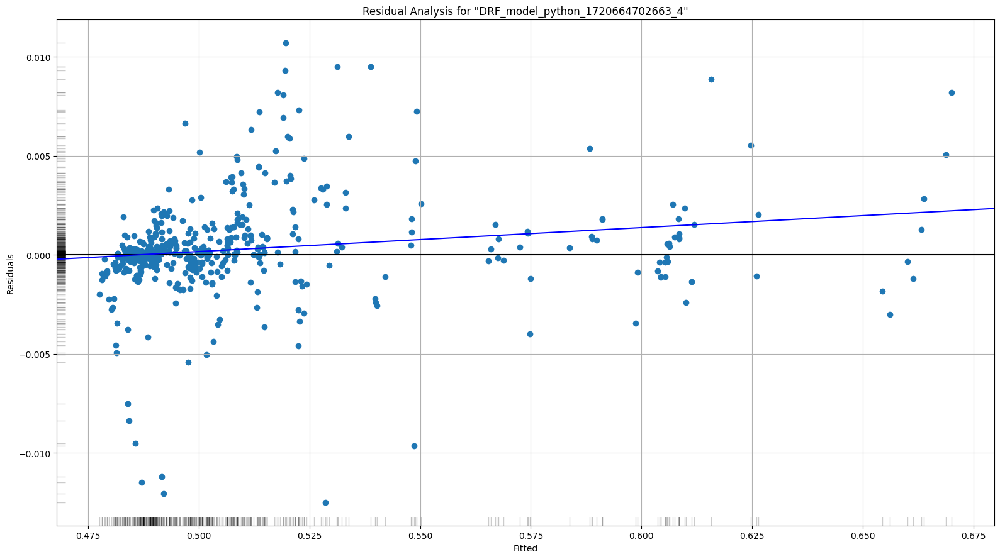

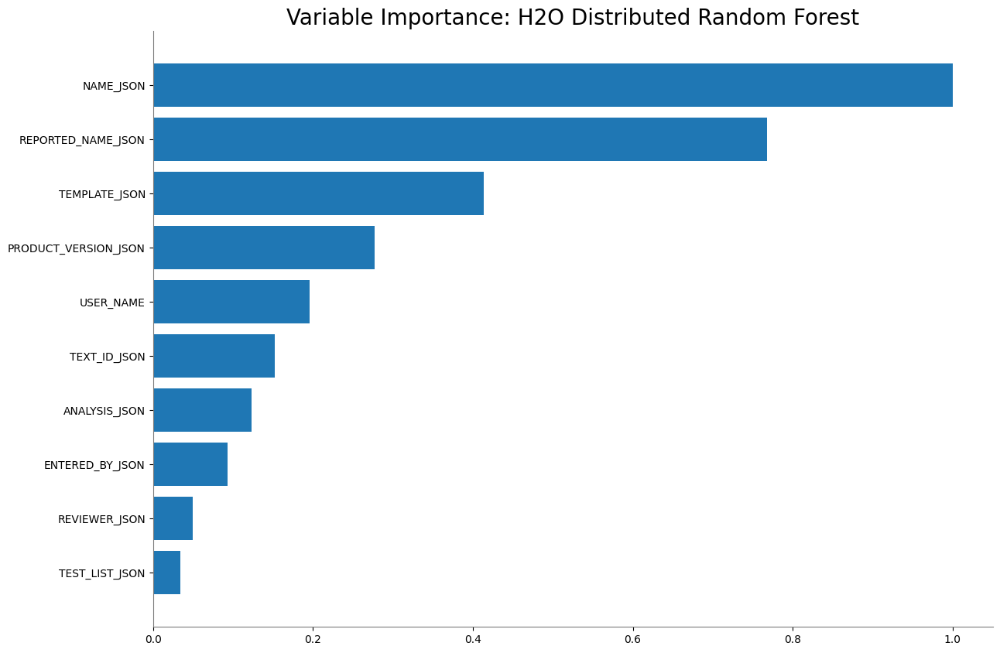

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, AUTO_CALC_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, AUTO_CALC_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

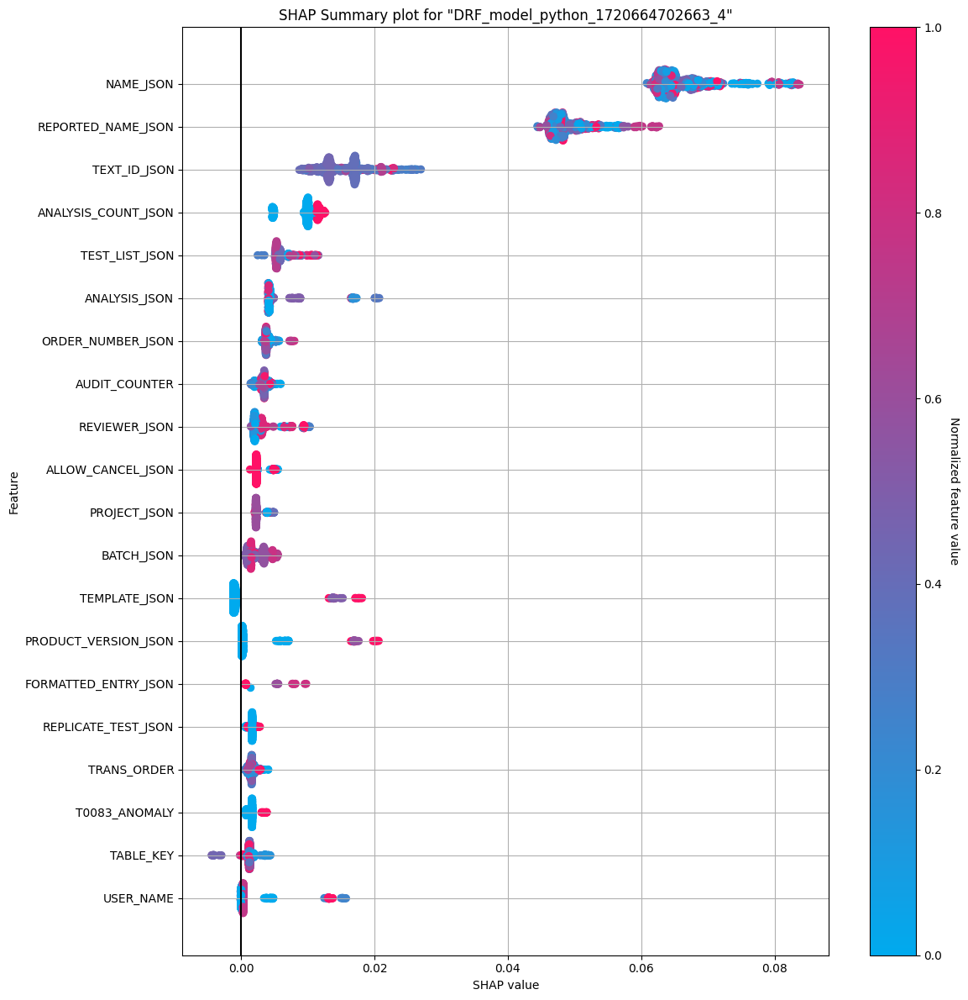

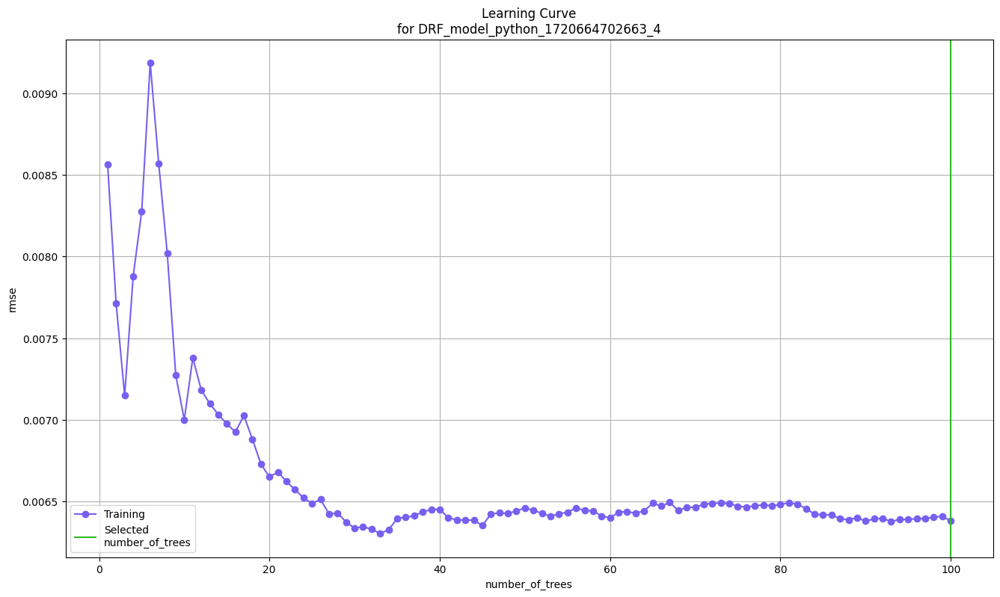

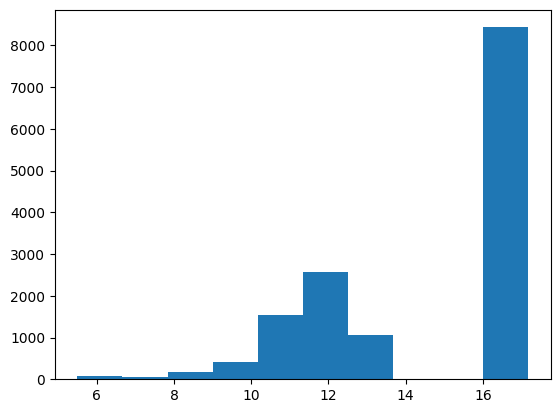

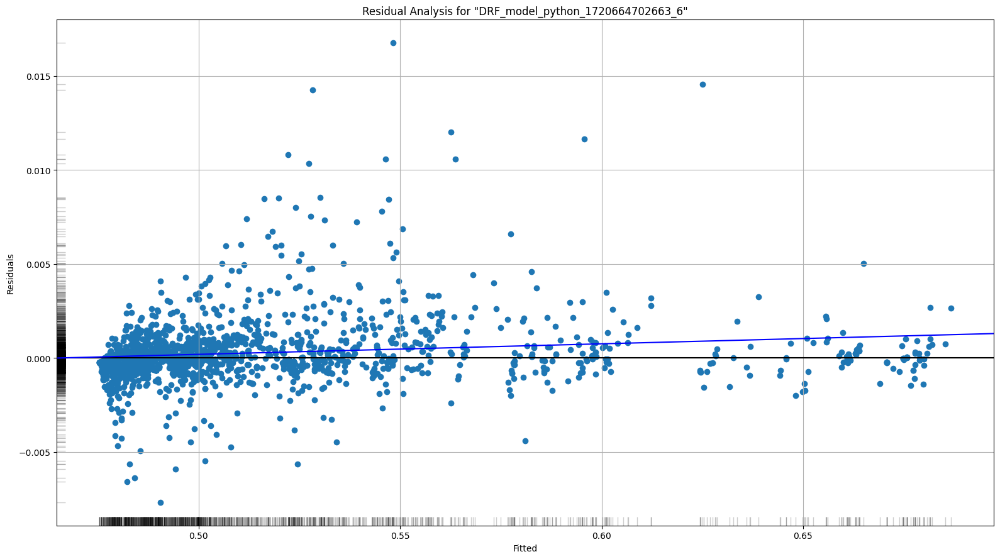

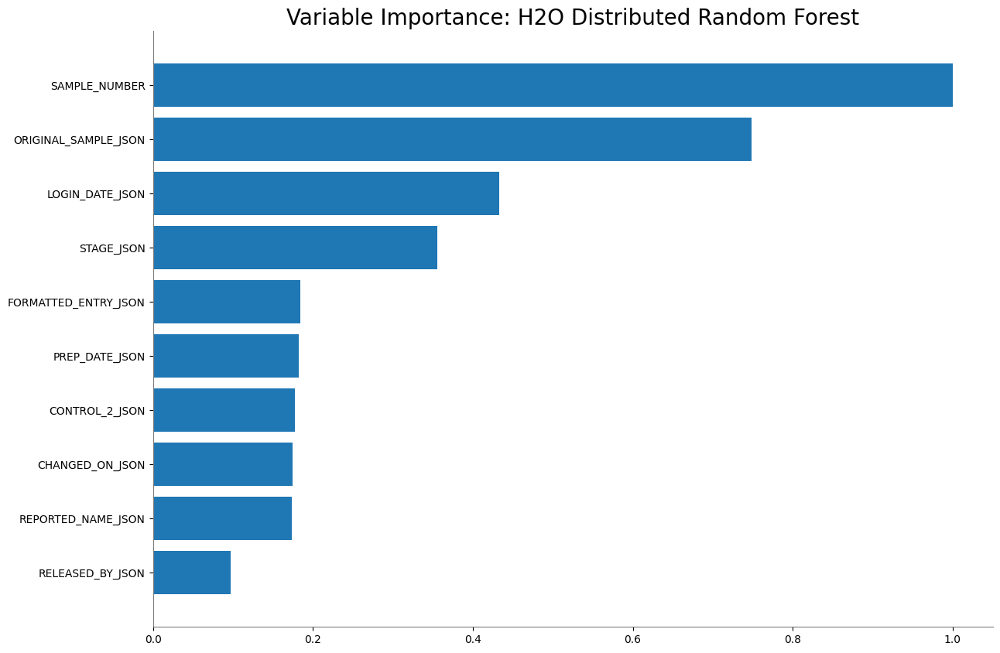

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PREP_JSON, RELEASED_JSON, OPTIONAL_JSON, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, REPLICATE_TEST_JSON, ALLOW_OUT_JSON, LOT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, SAMPLE_TYPE_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, OPTIONAL_JSON, FACTOR_OPERATOR_JSON, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, AUTO_CALC_JSON, RELEASED_ON_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, ANALYSIS_COUNT_JSON, REPLICATE_TEST_JSON, RELEASED_BY_JSON, ALLOW_OUT_JSON, LOT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, SAMPLE_TYPE_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

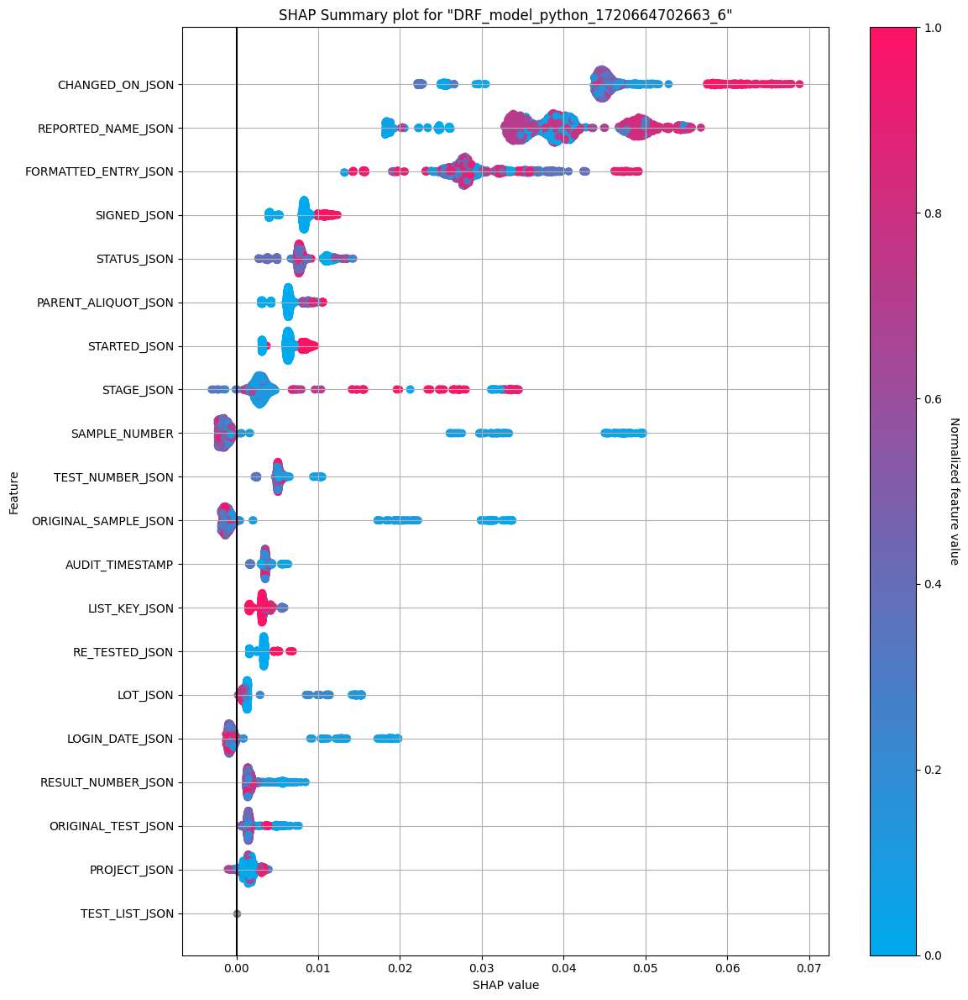

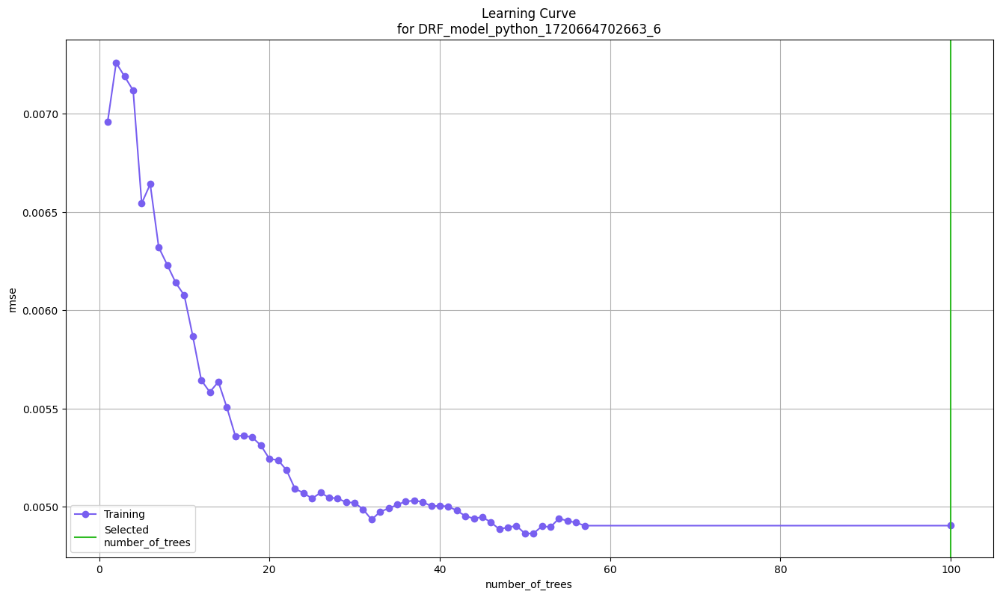

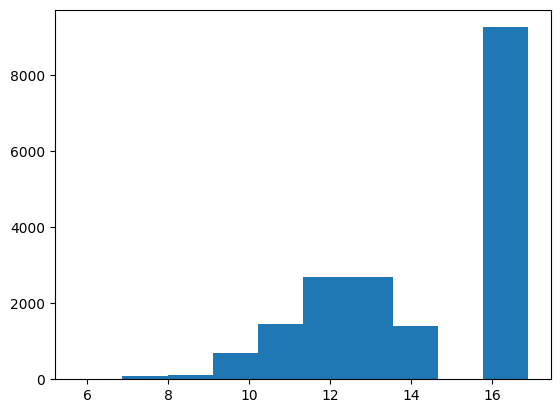

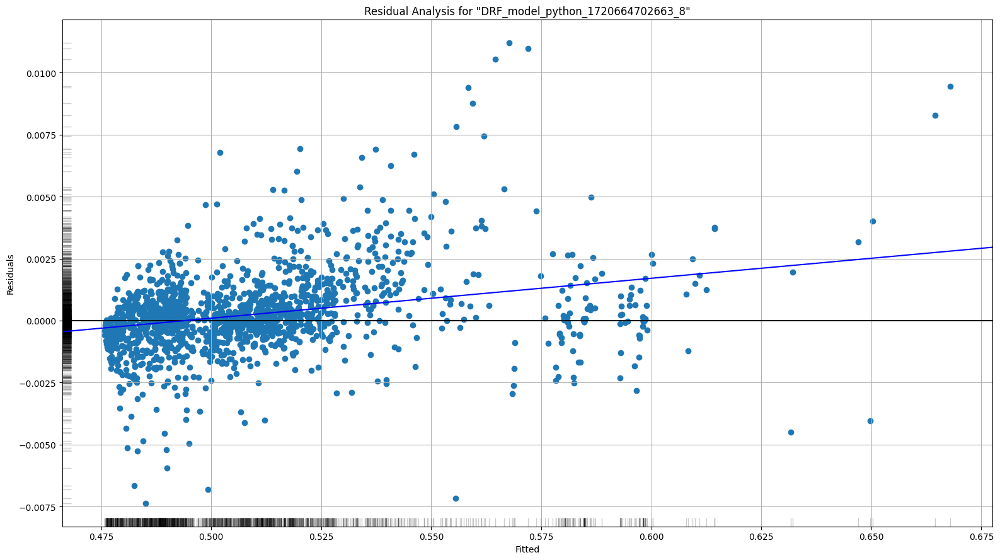

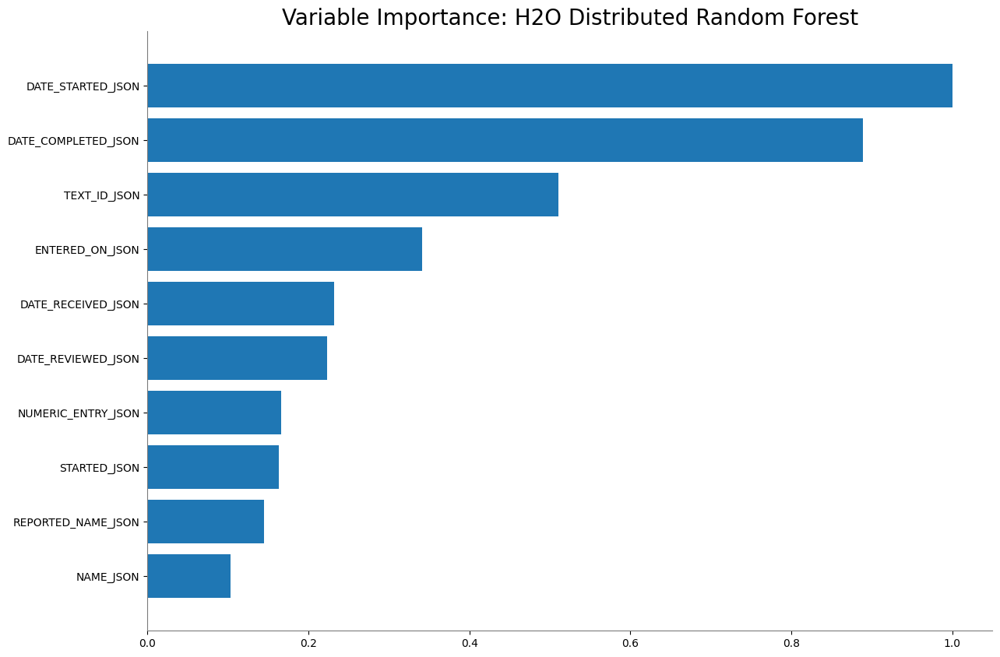

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, RELEASED_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

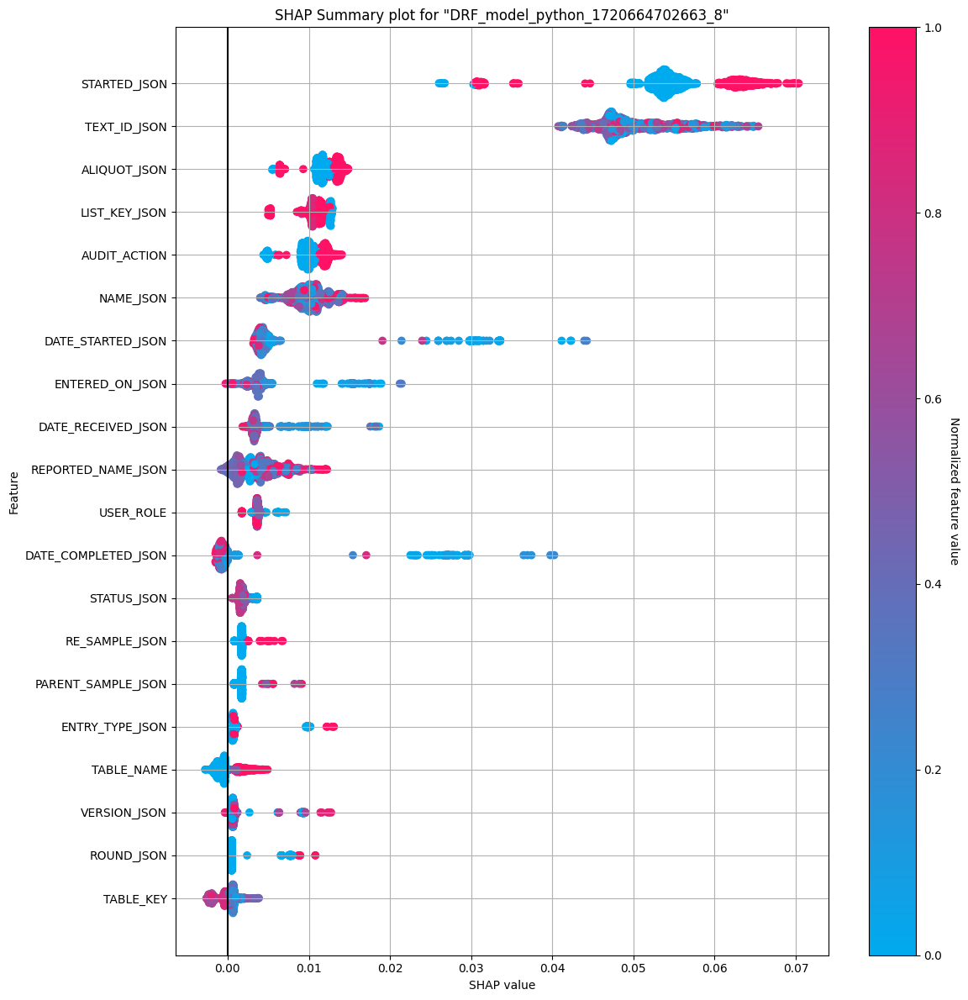

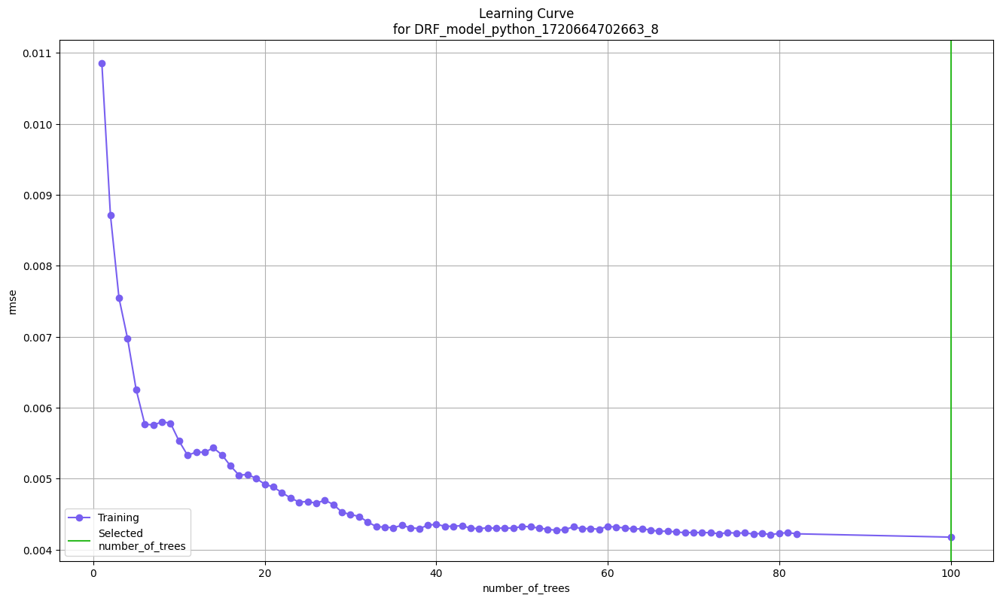

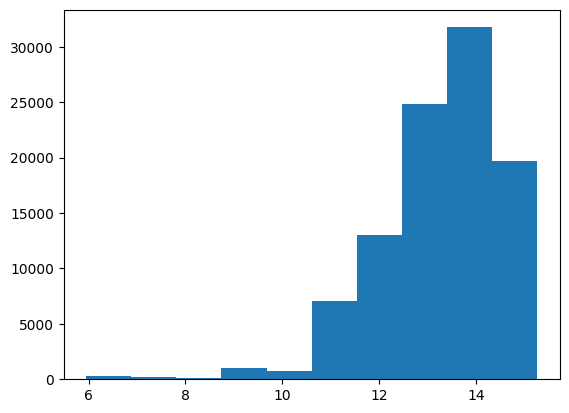

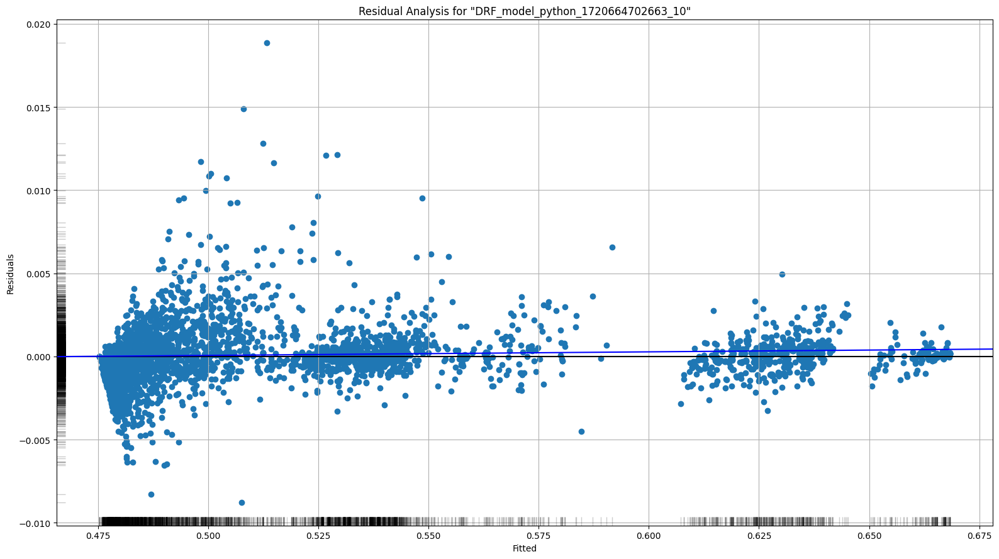

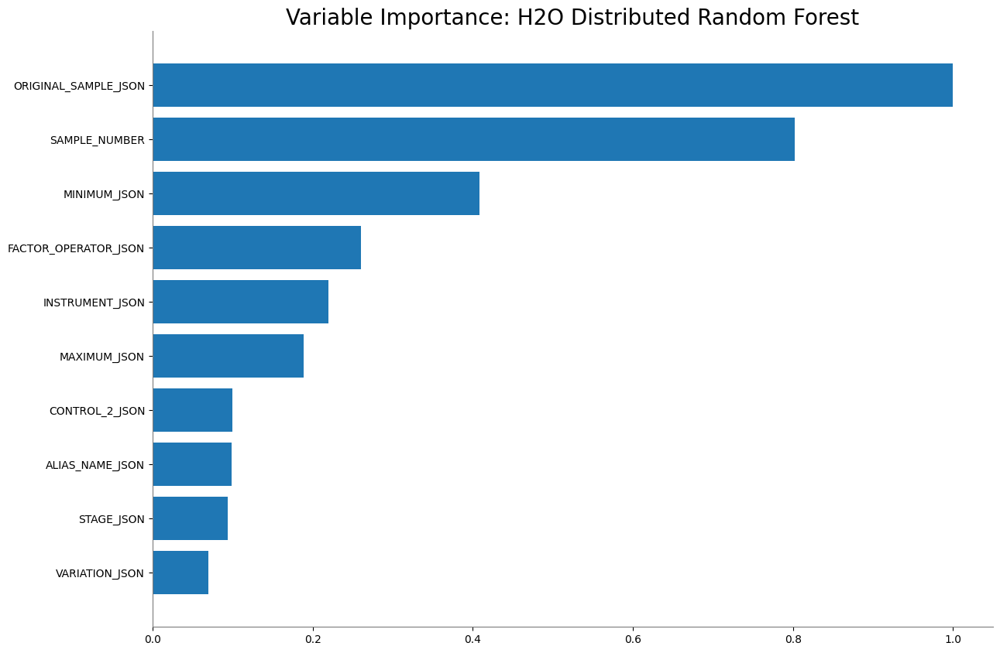

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, STARTED_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, STARTED_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

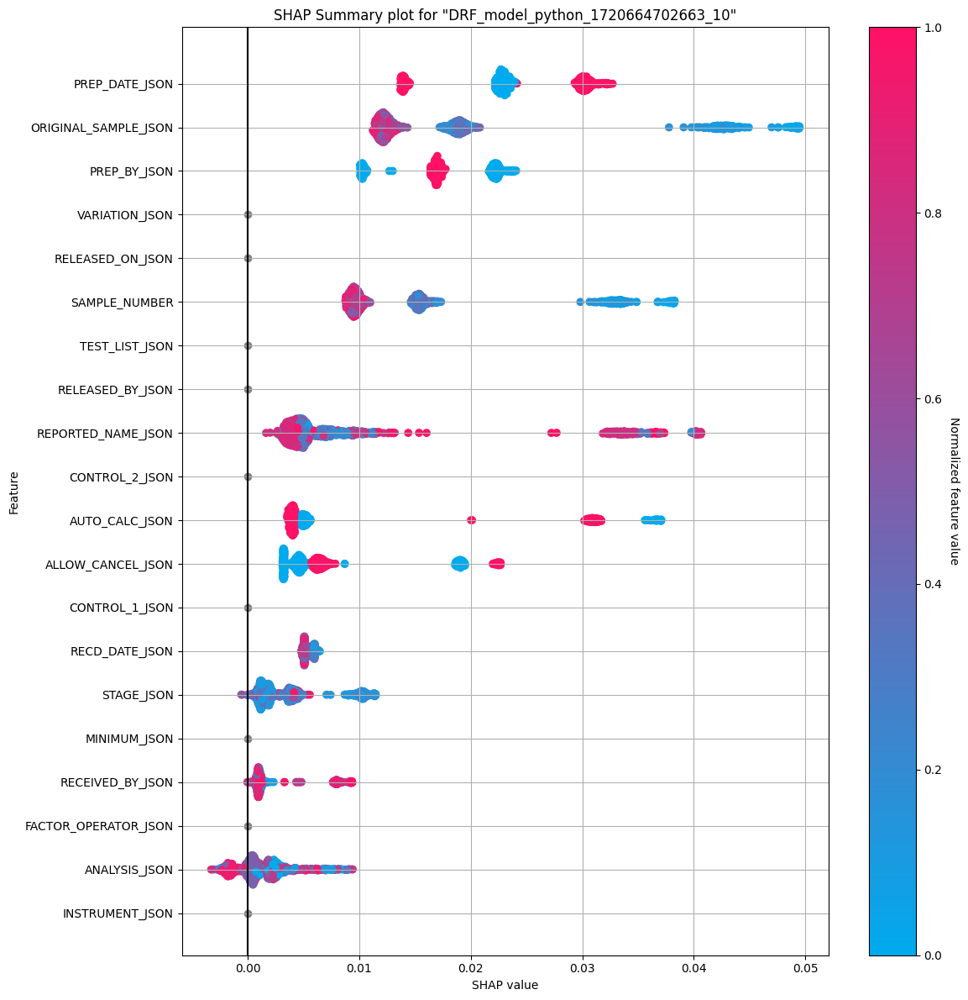

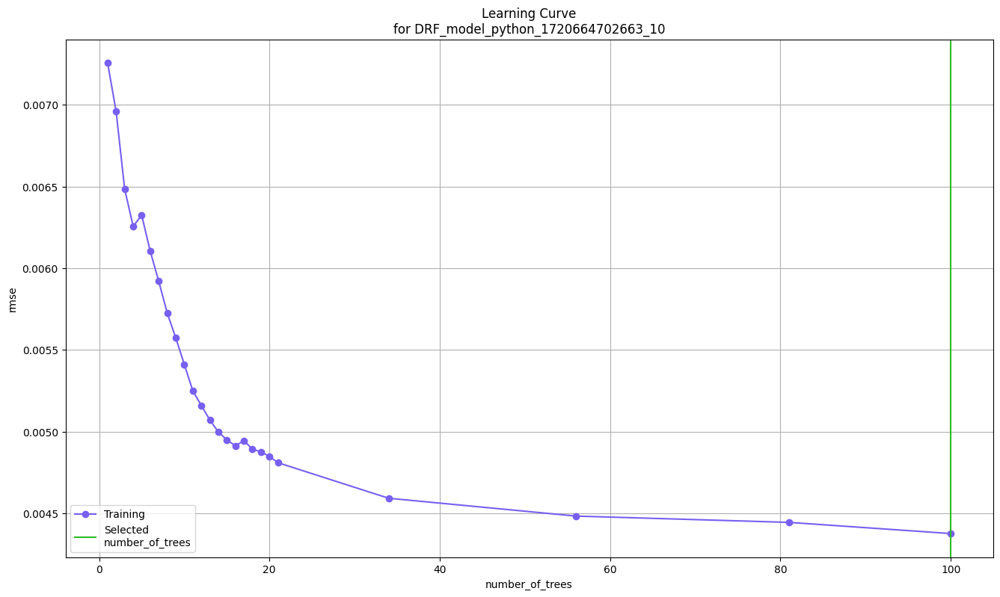

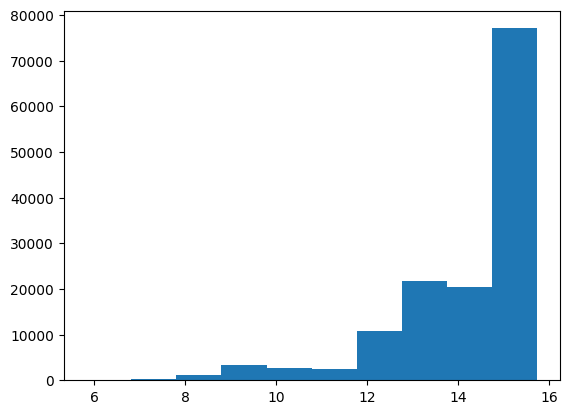

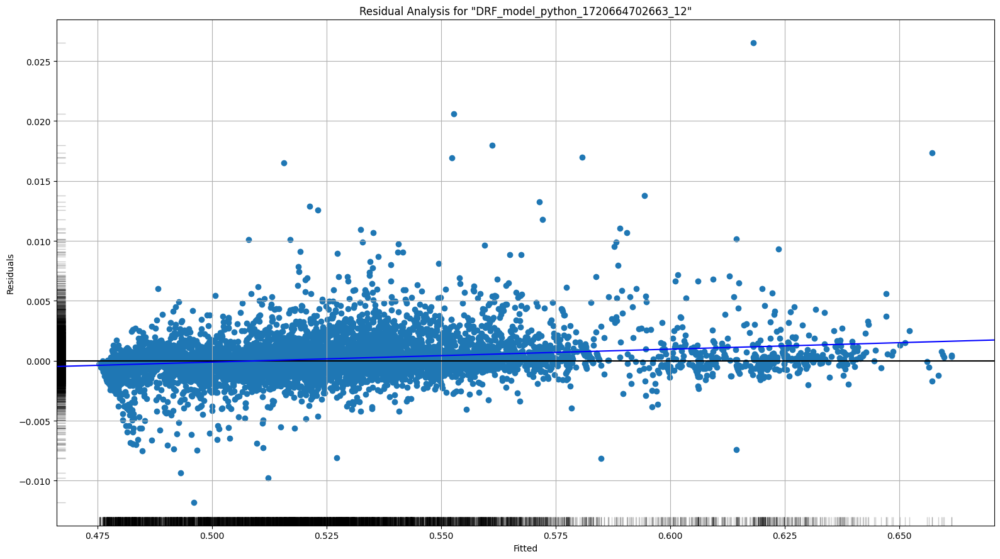

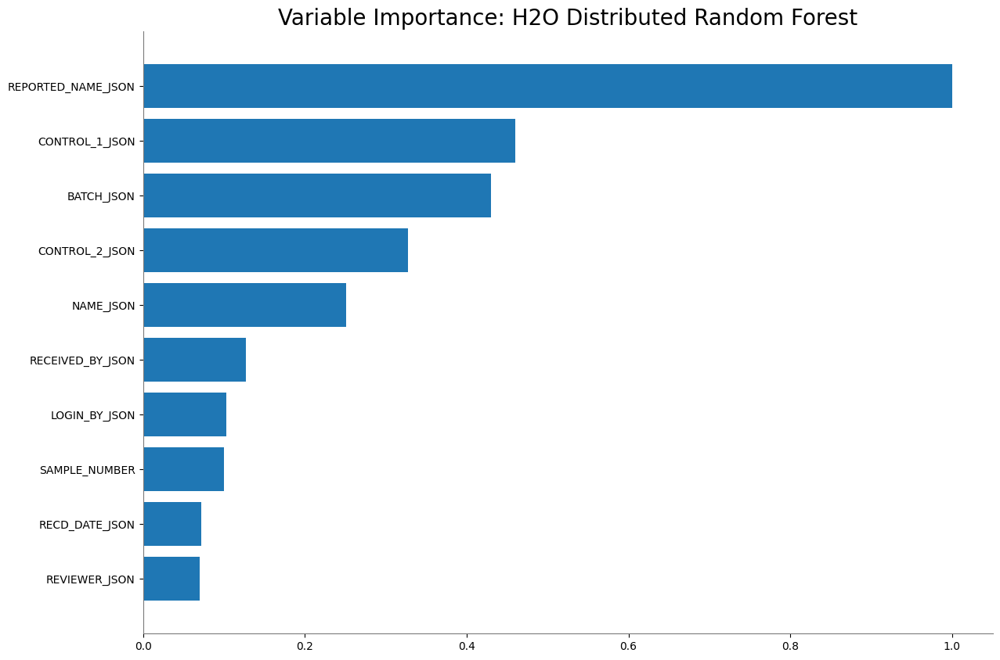

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [AUDIT_TYPE, BATCH_PARENT_TEST_JSON, PARENT_TEST_JSON, TEXT_ID_JSON, ANALYSIS_COUNT_JSON, CHARGE_ENTRY_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON, T0083_ANOMALY]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, TEXT_ID_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

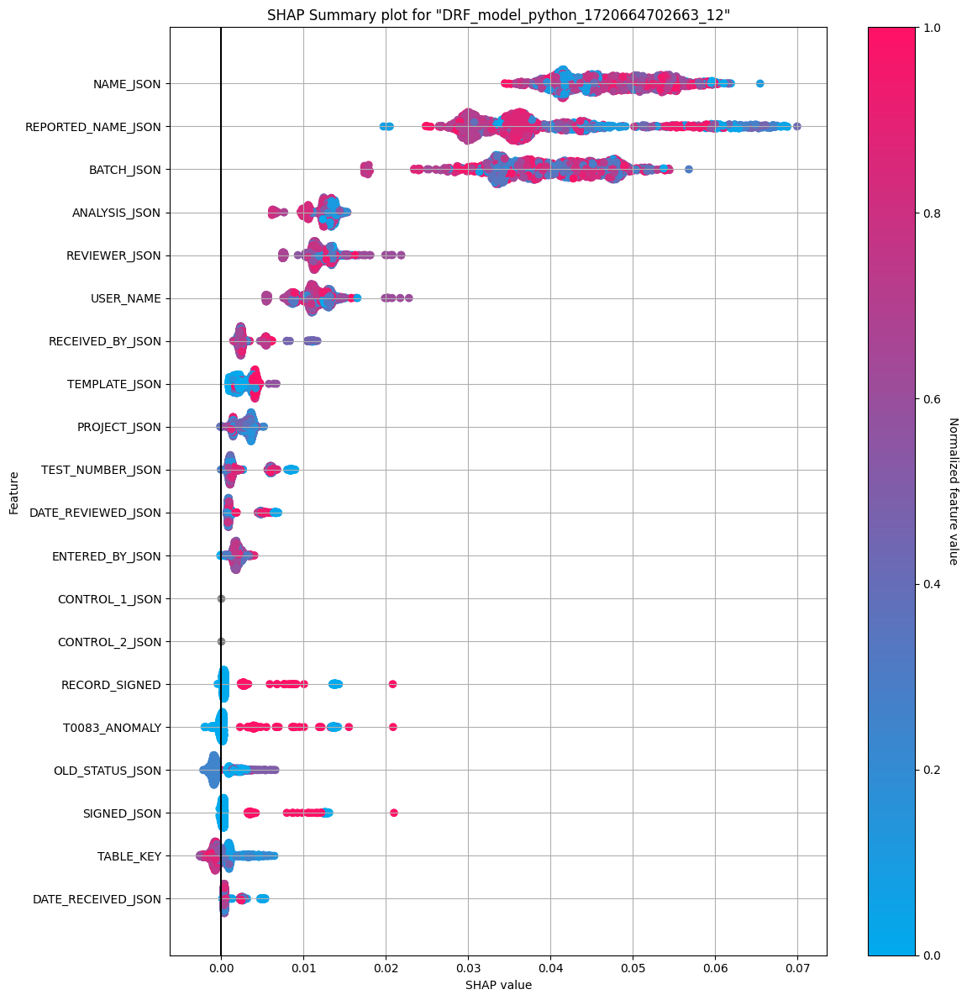

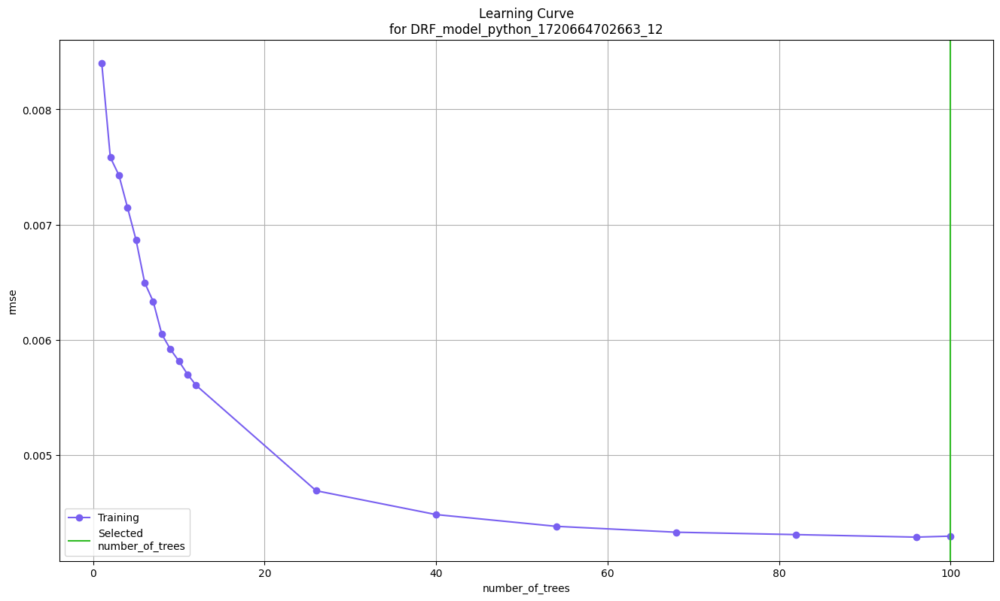

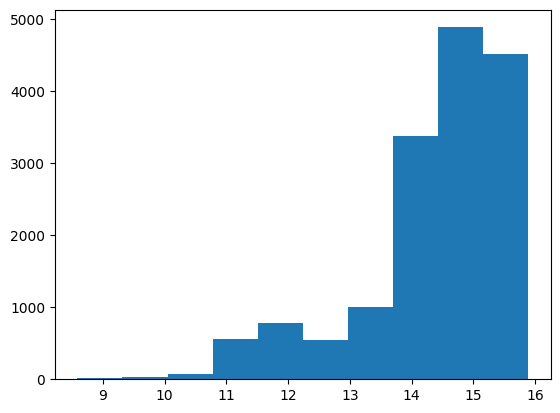

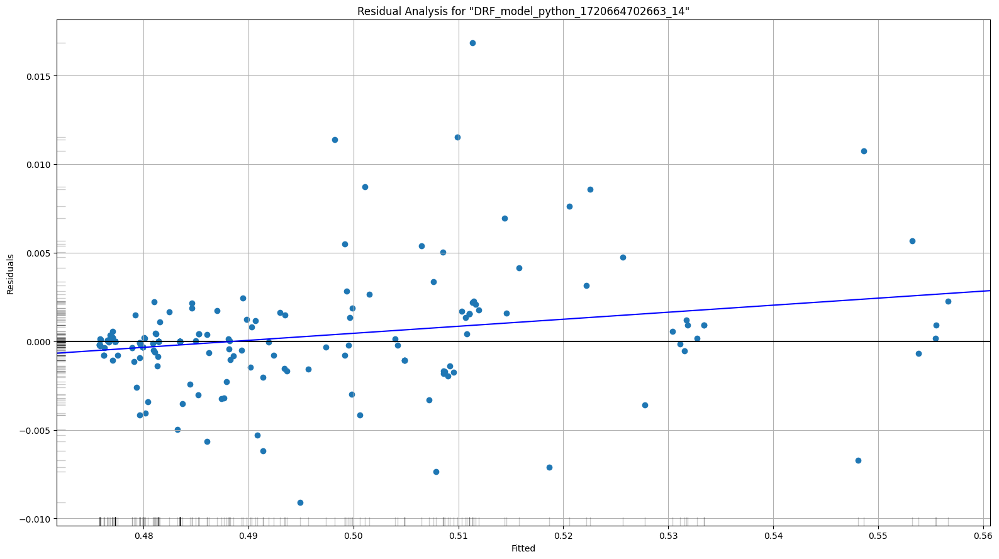

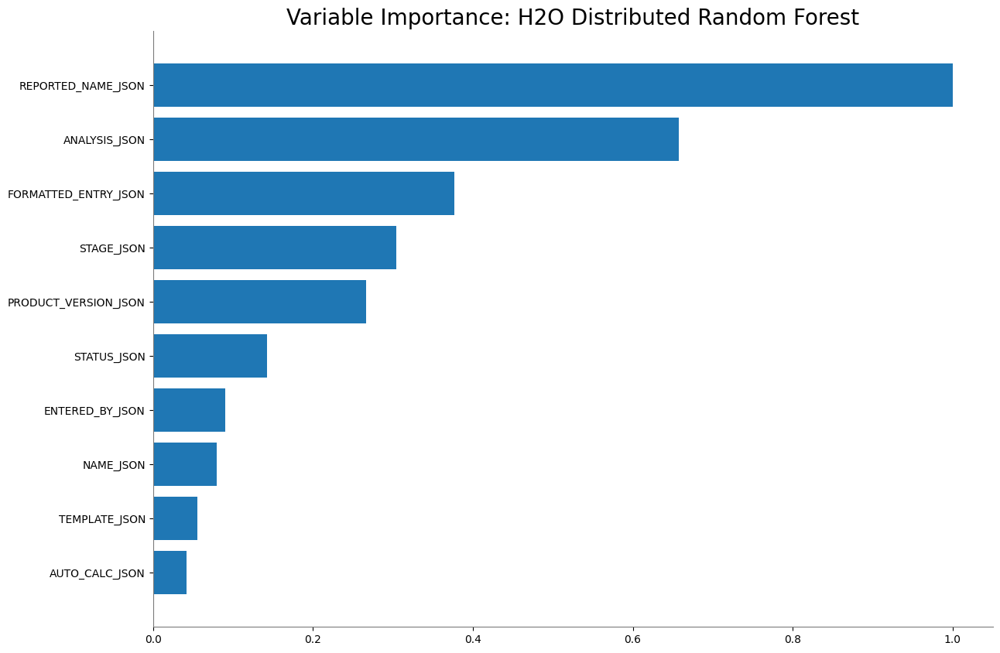

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PREP_JSON, RELEASED_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, DISPLAYED_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, OPTIONAL_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

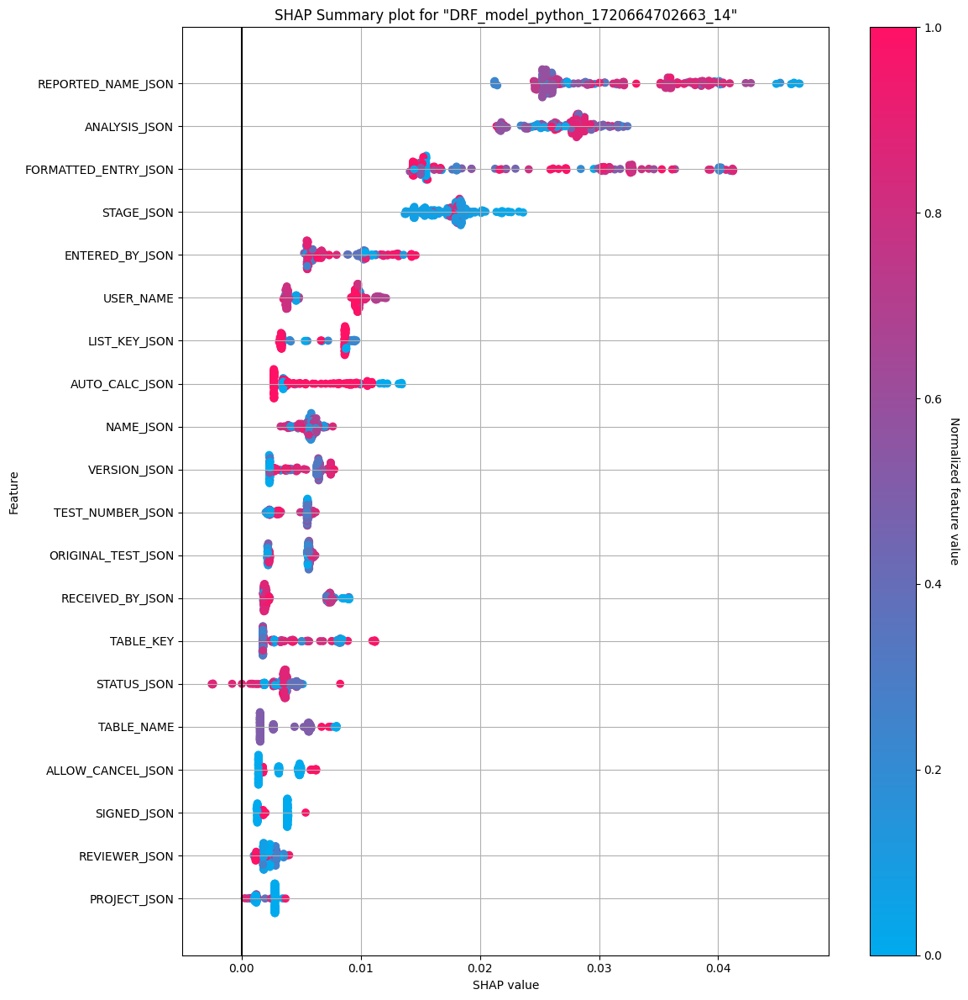

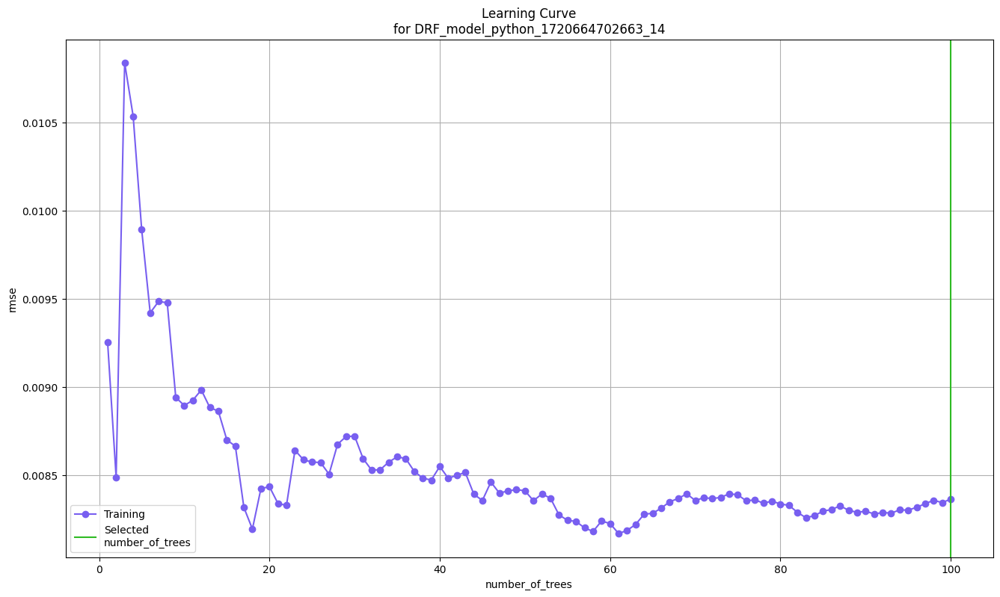

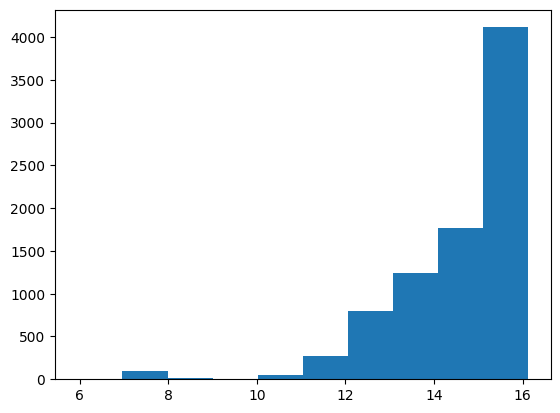

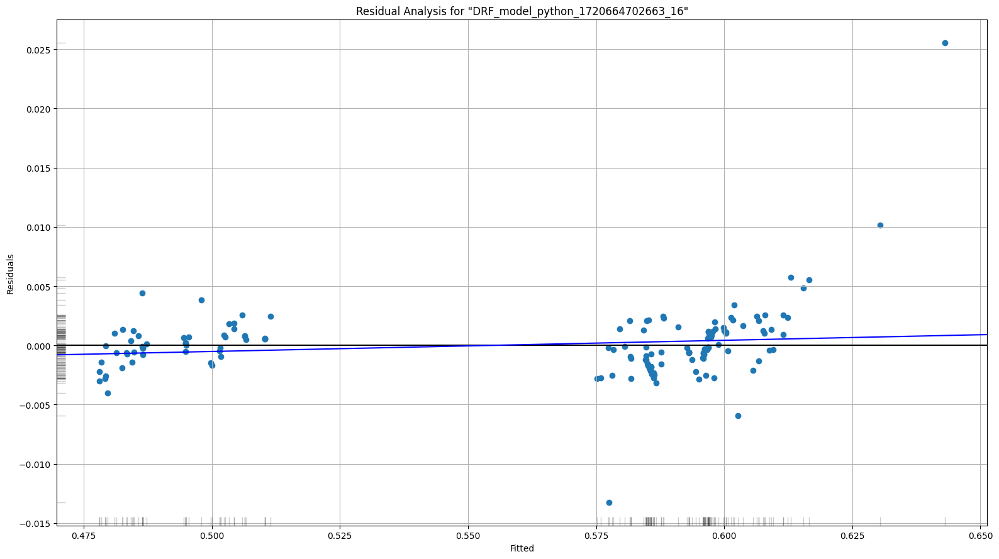

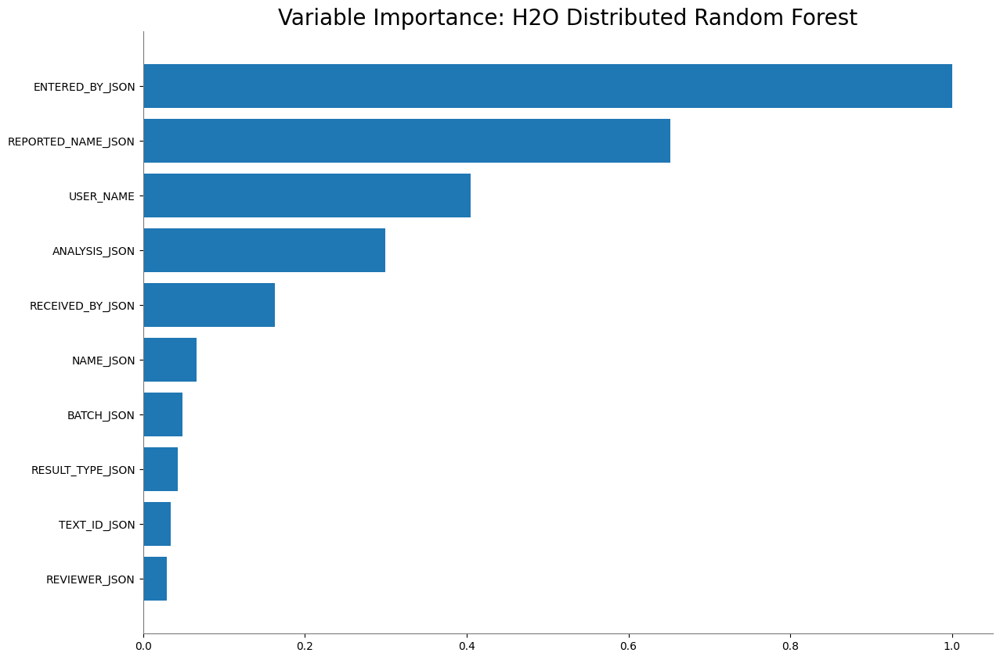

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, STATUS_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

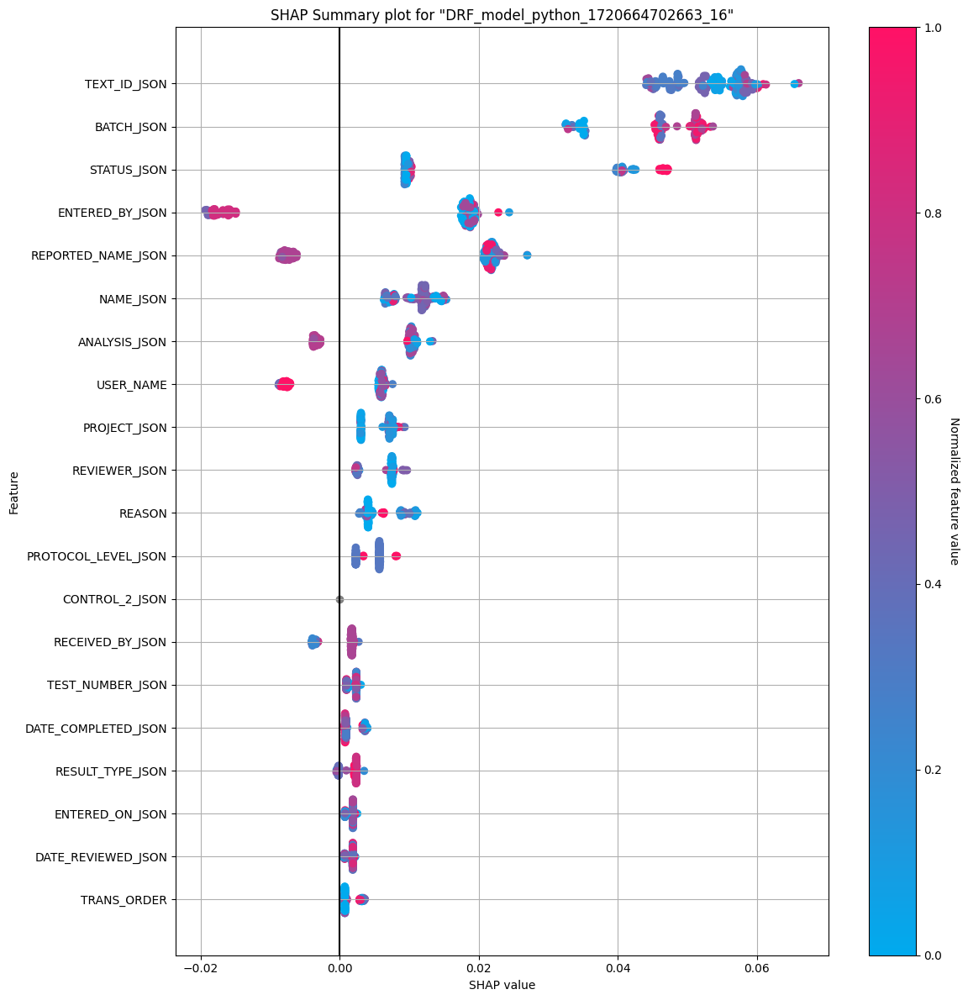

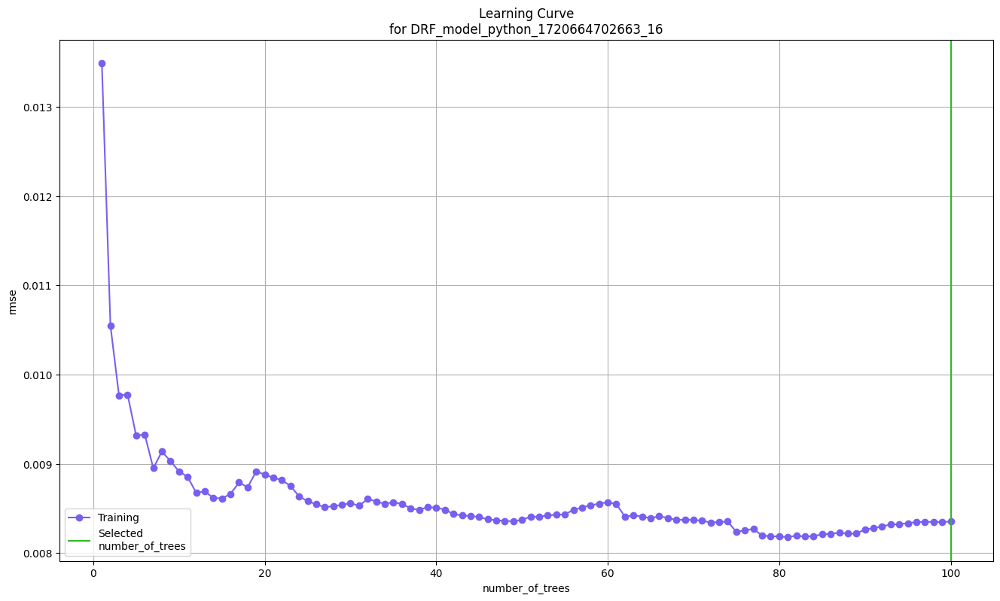

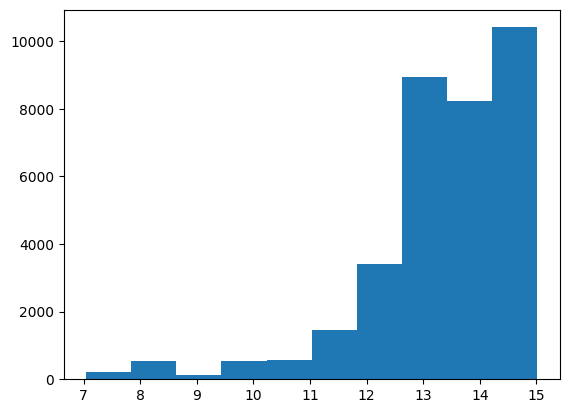

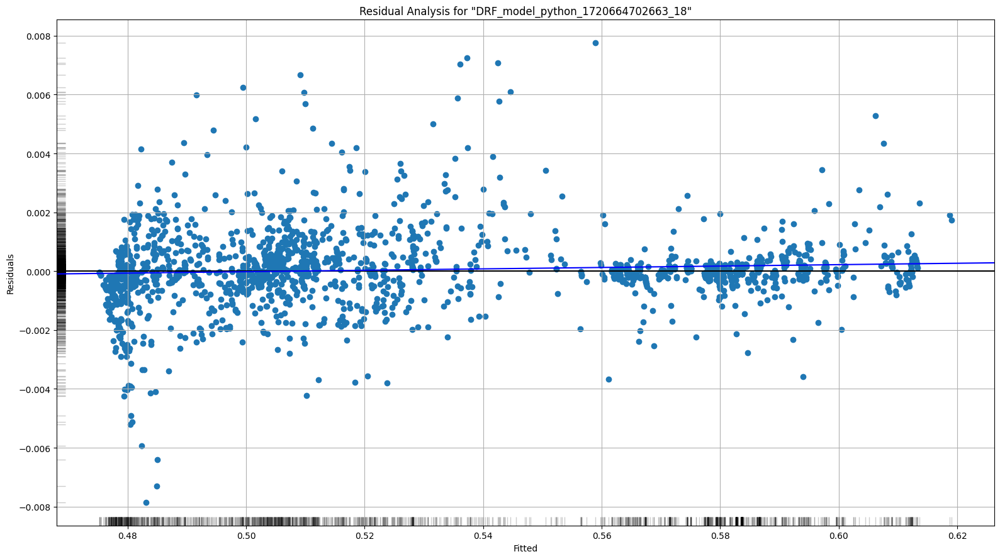

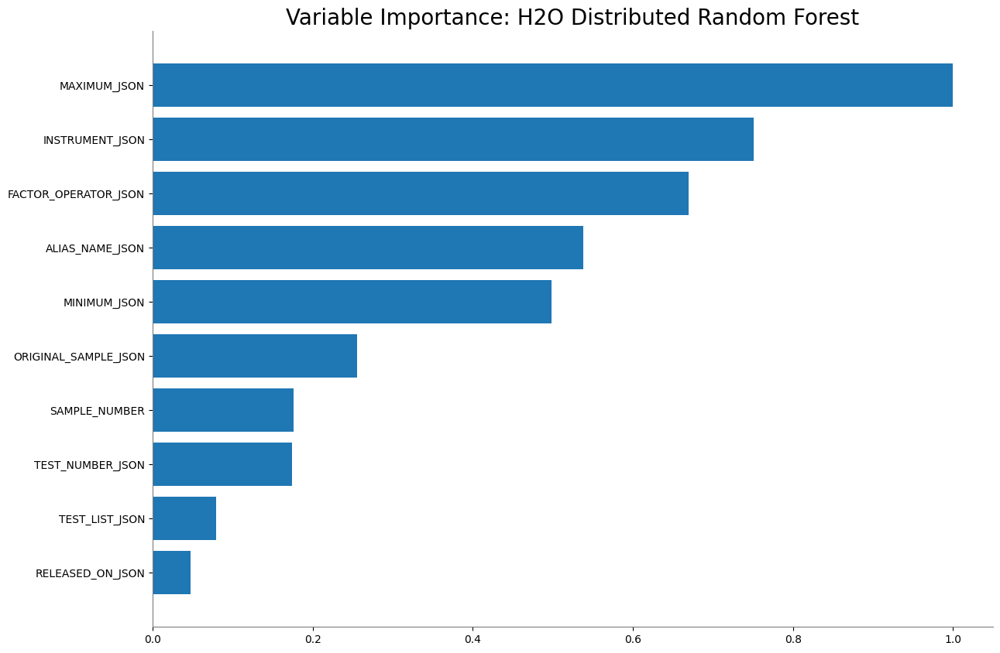

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PREP_JSON, RELEASED_JSON, OPTIONAL_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, STATUS_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, OPTIONAL_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, ANALYSIS_COUNT_JSON, STATUS_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

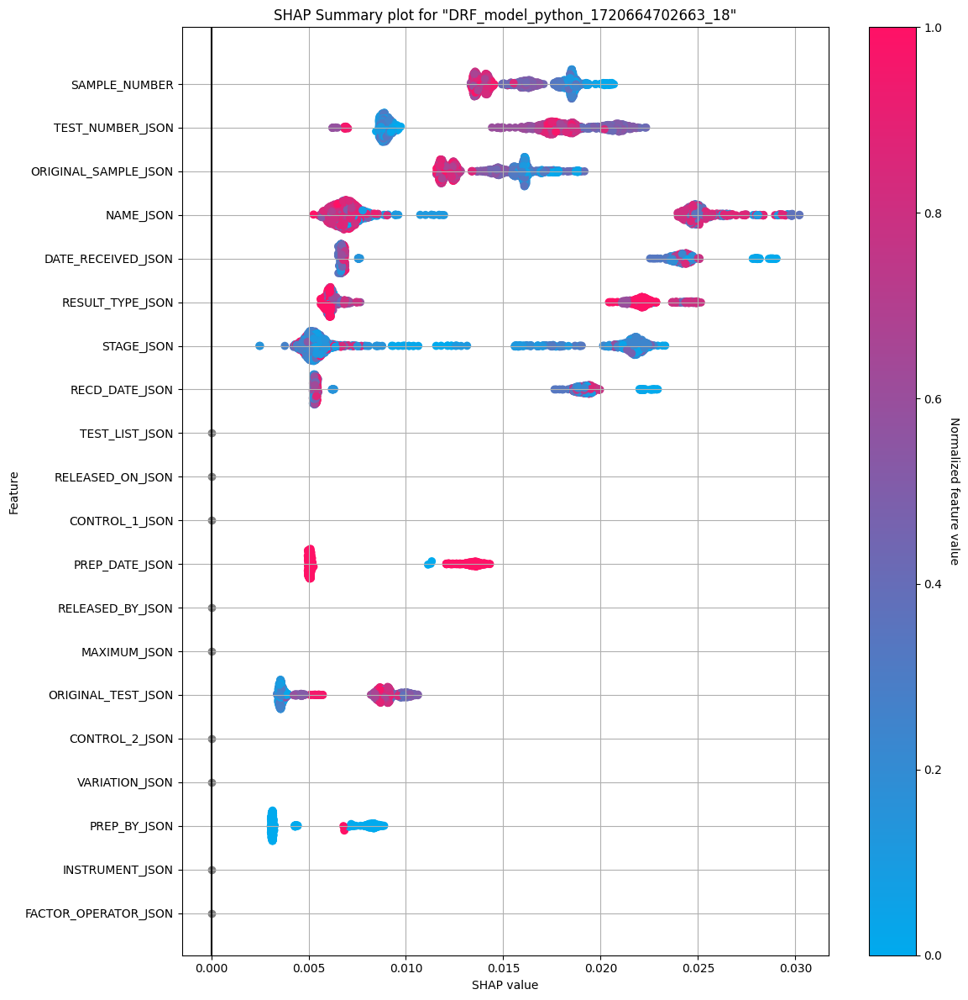

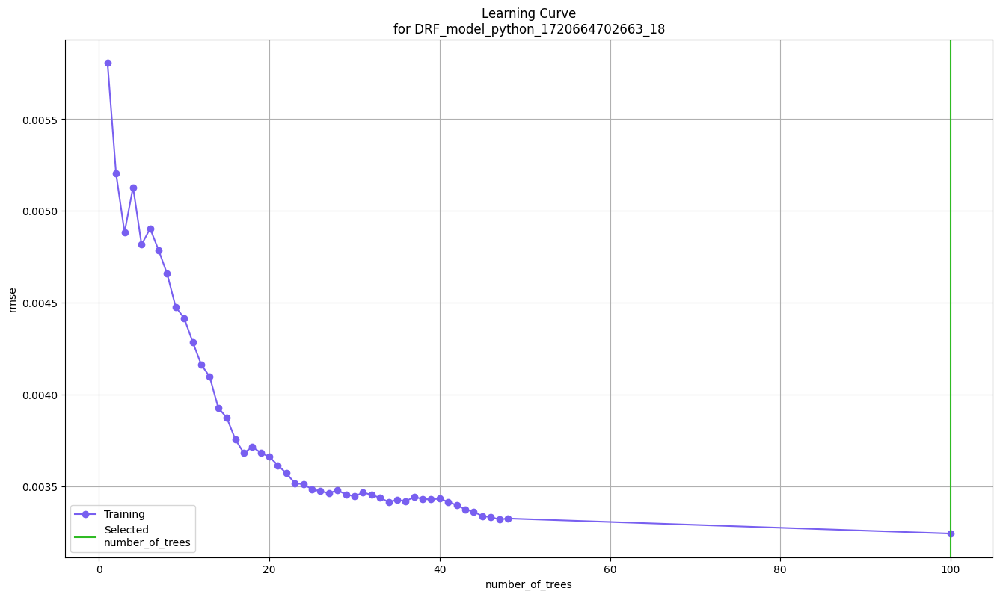

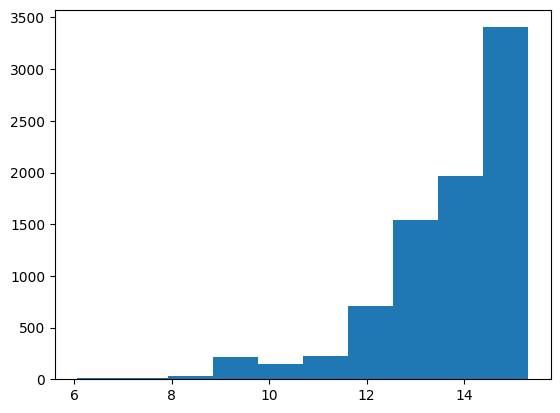

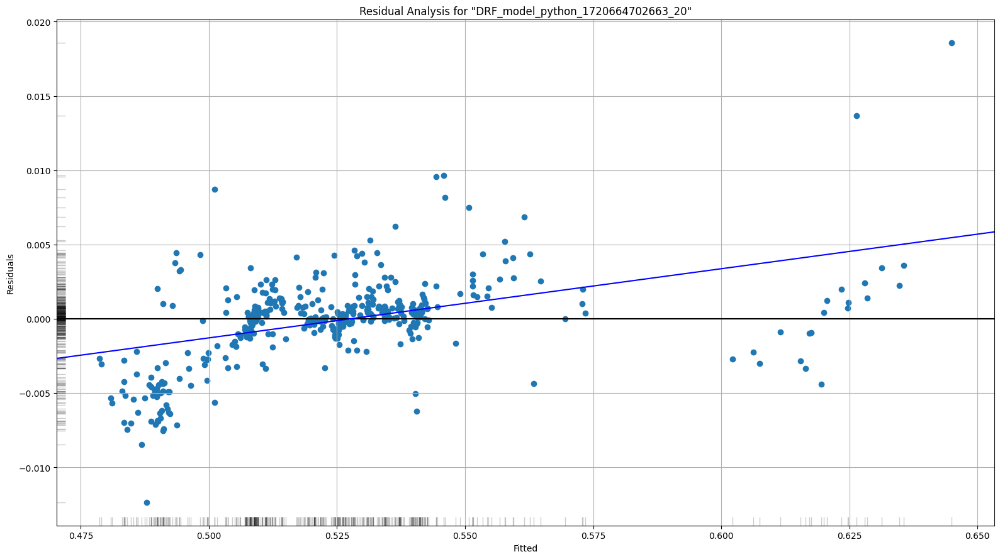

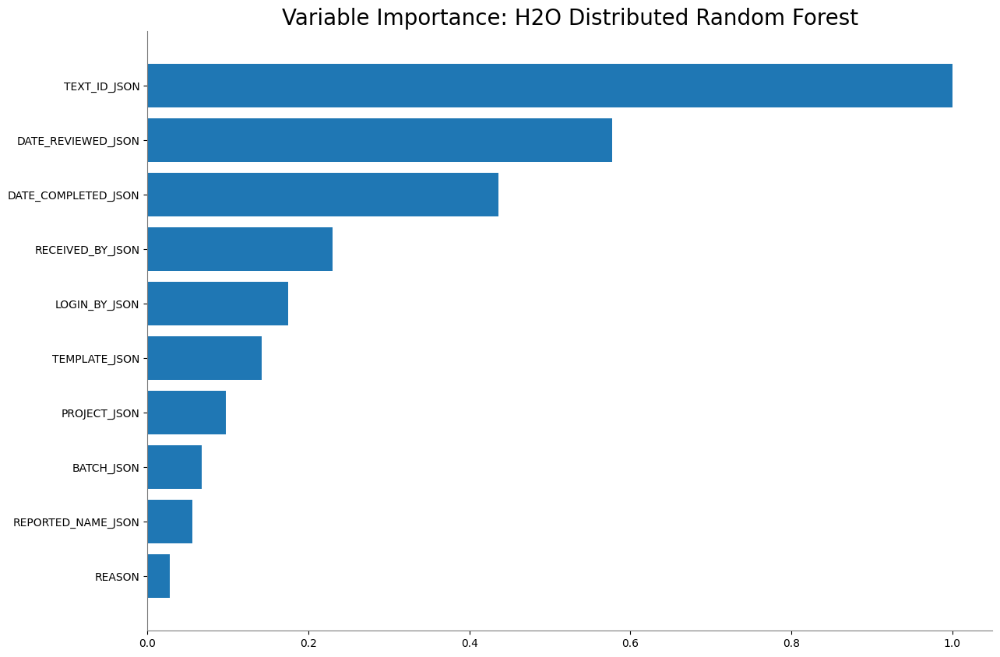

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, T0083_ANOMALY, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, T0083_ANOMALY, HAS_ATTRIBUTES_JSON, AUTO_CALC_JSON, RELEASED_ON_JSON, CONTROL_2_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, MINIMUM_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, TEST_LIST_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, INSTRUMENT_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, MAXIMUM_JSON, CONTROL_1_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

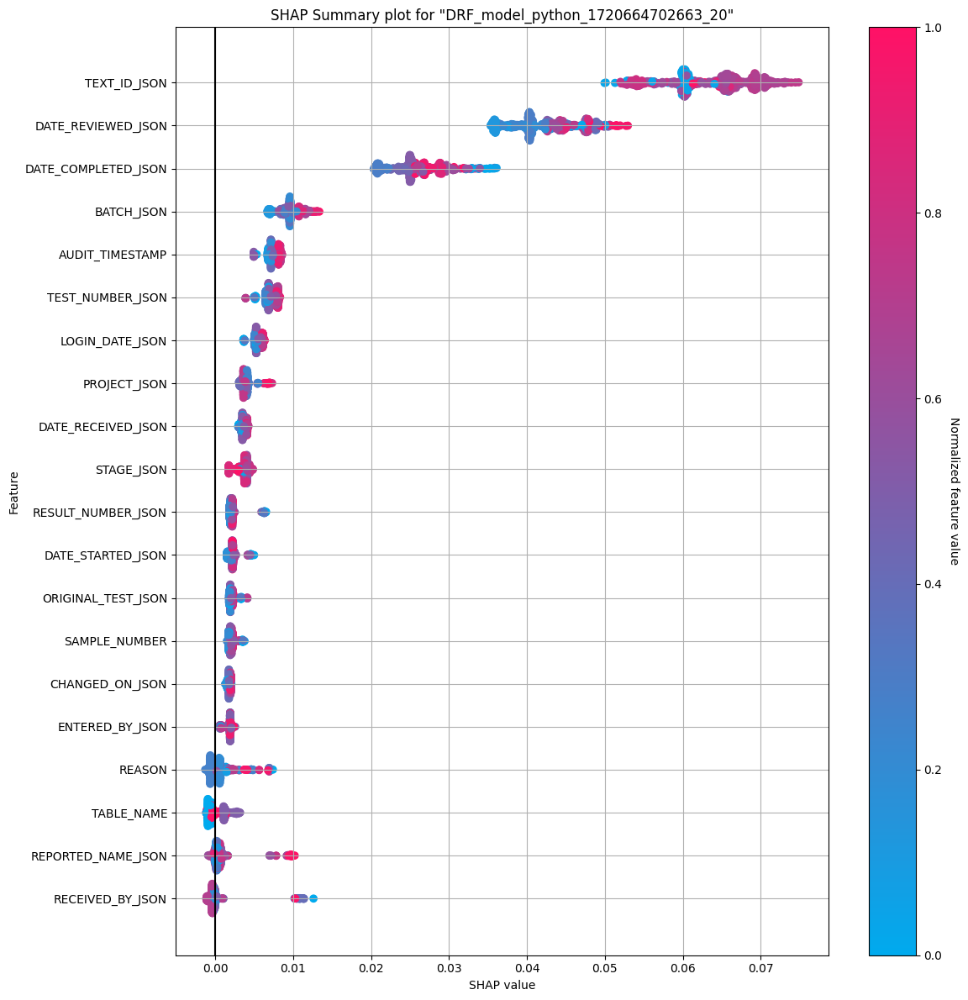

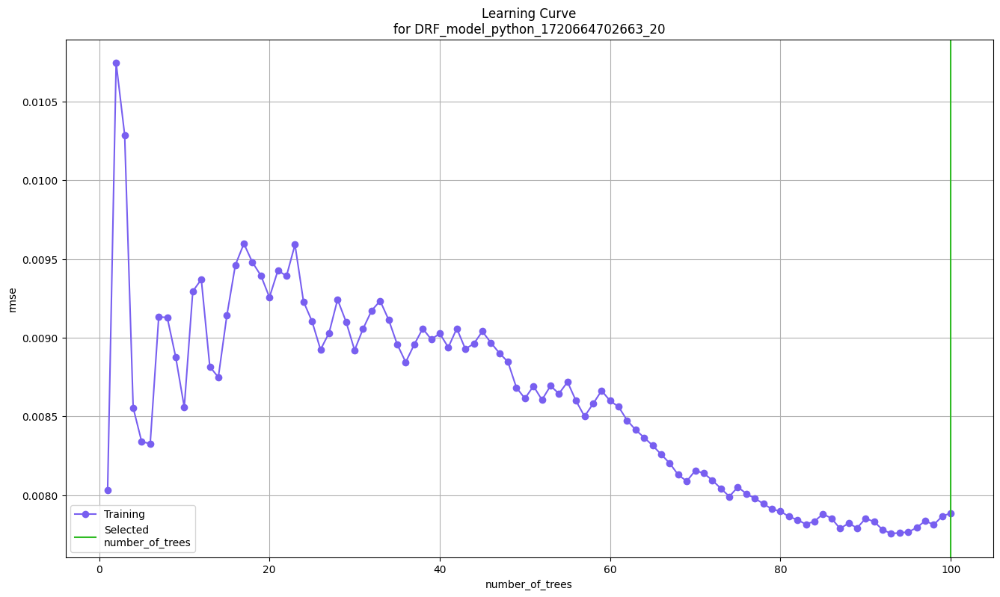

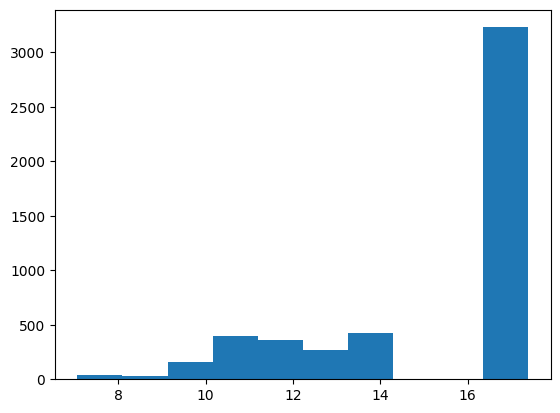

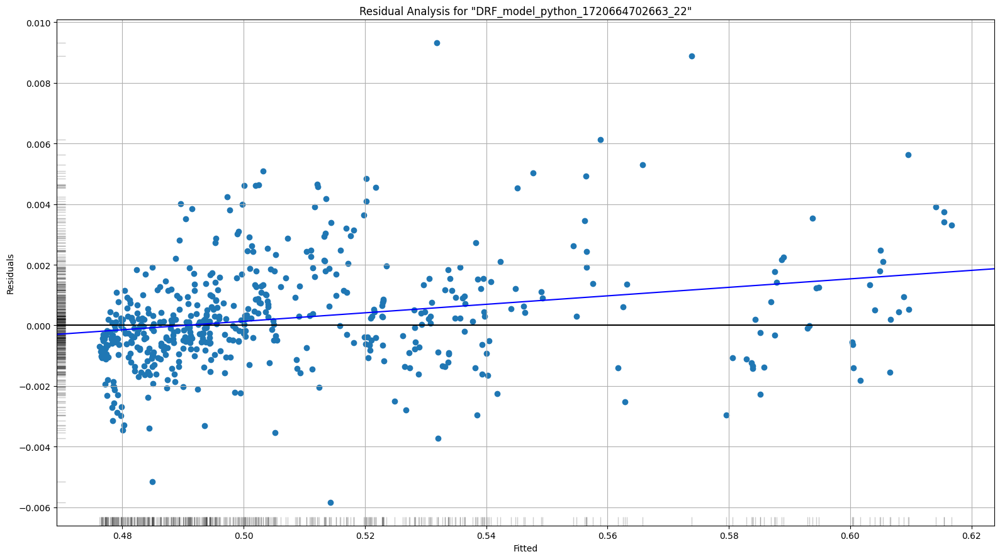

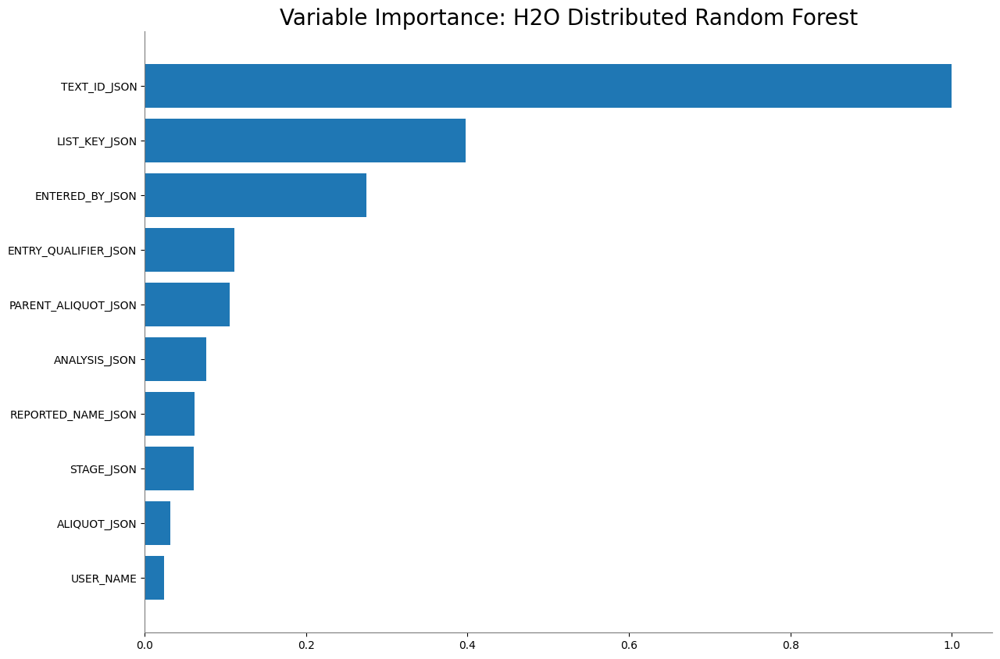

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

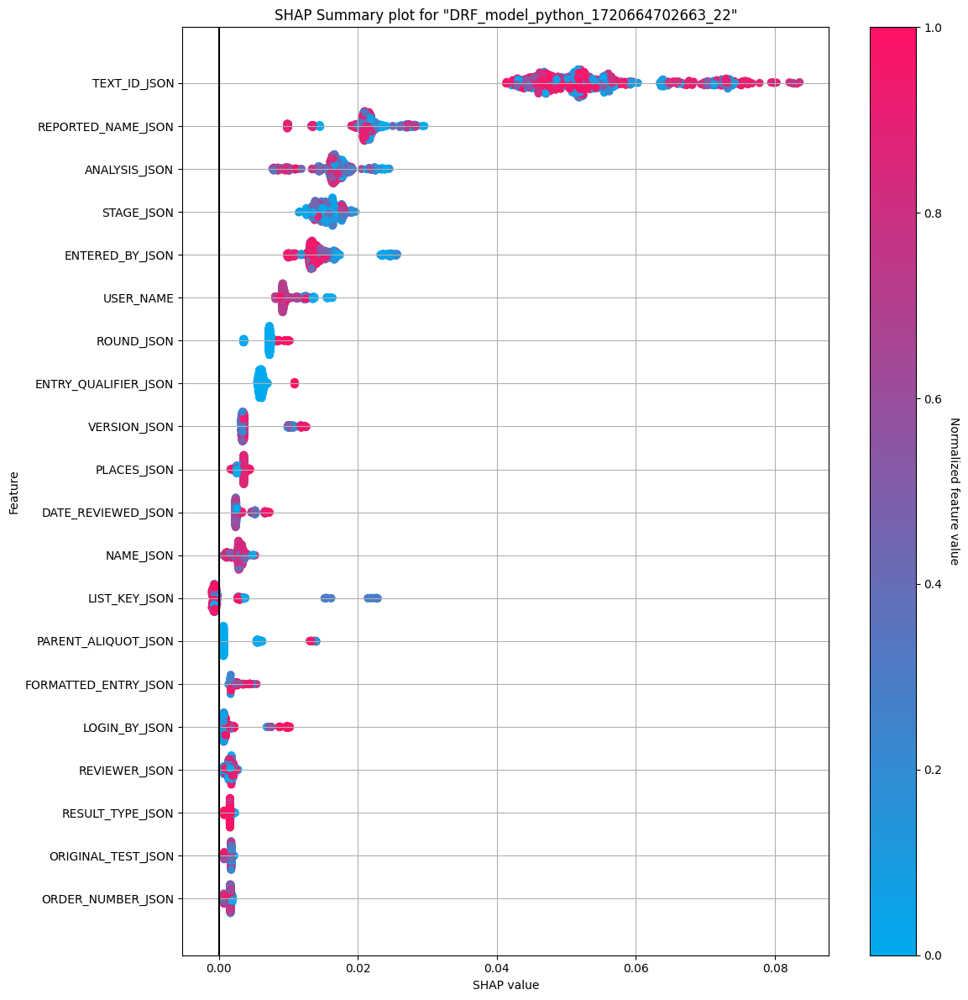

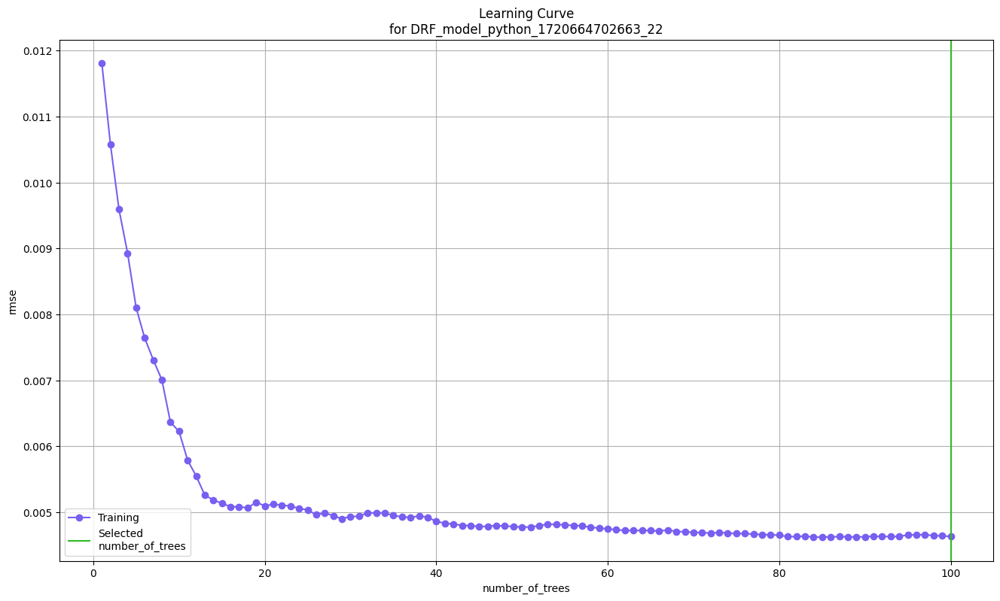

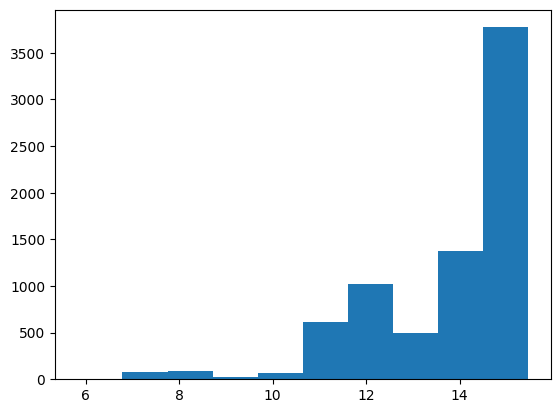

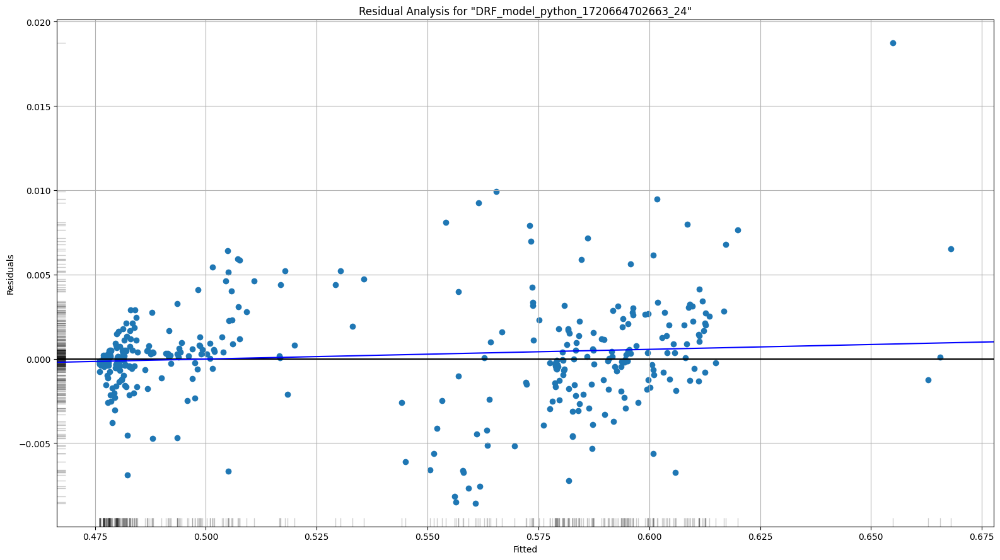

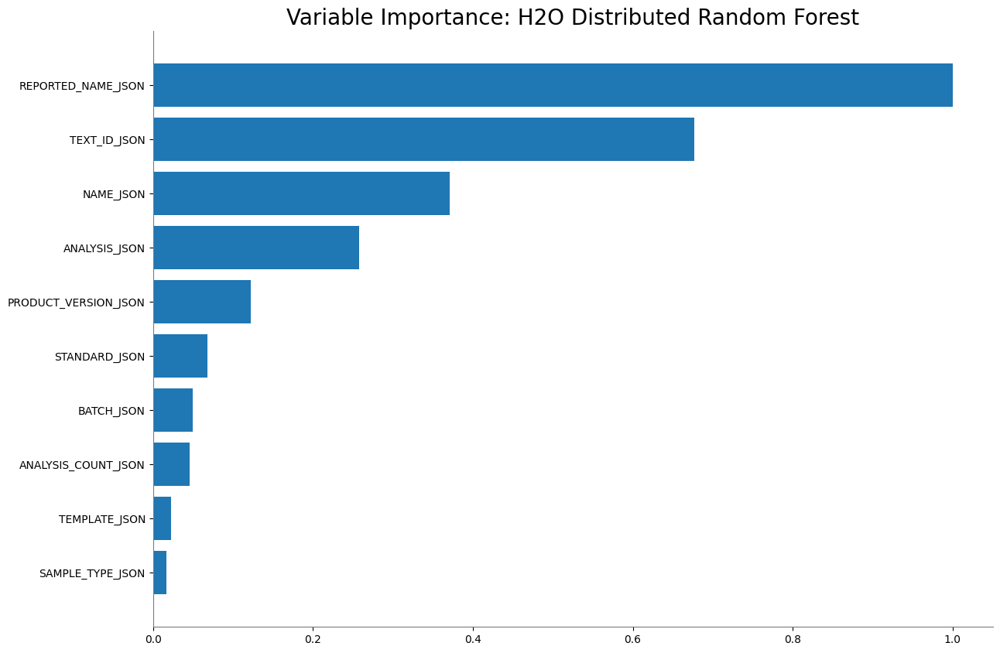

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, RELEASED_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

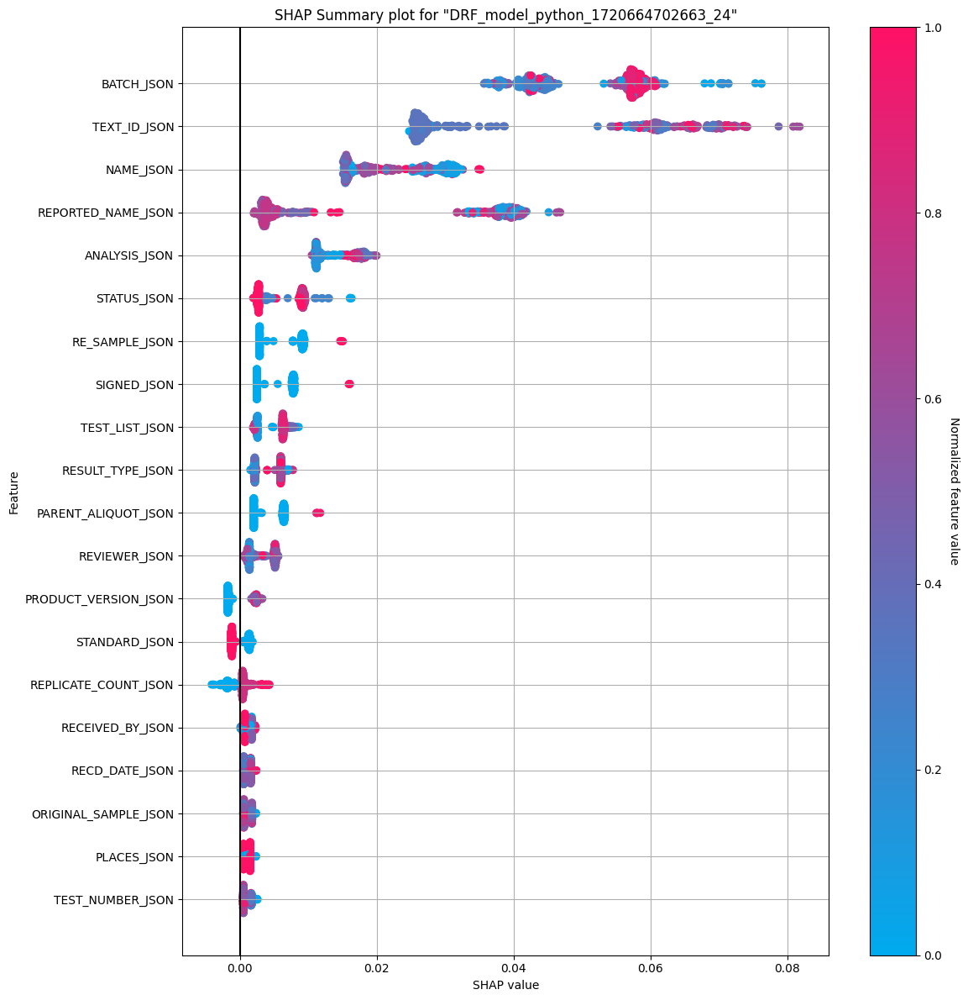

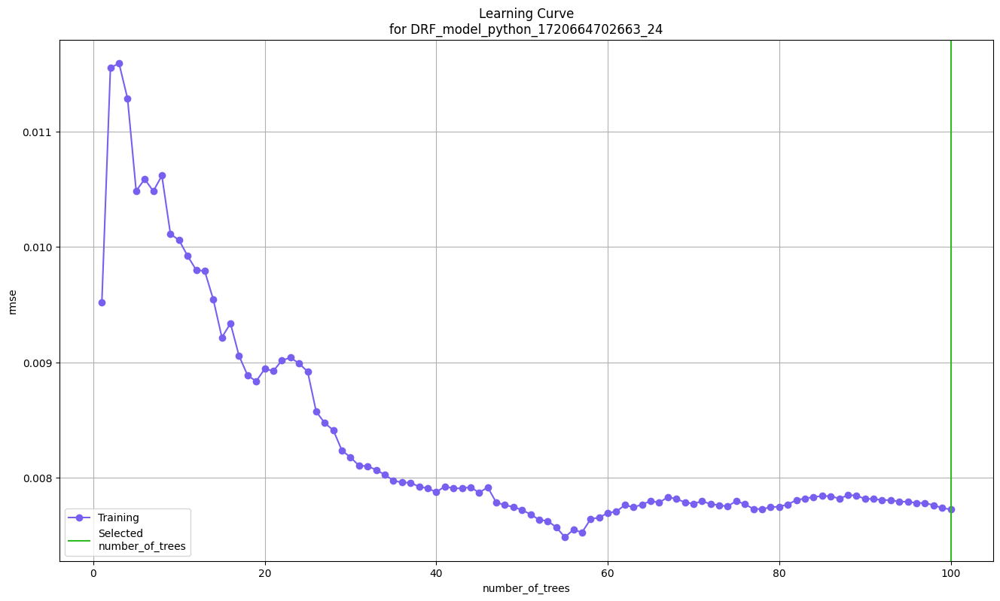

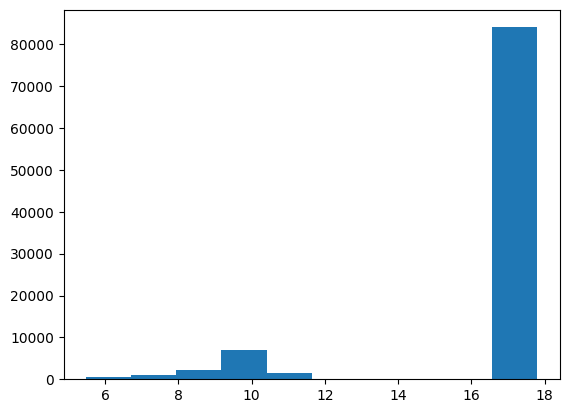

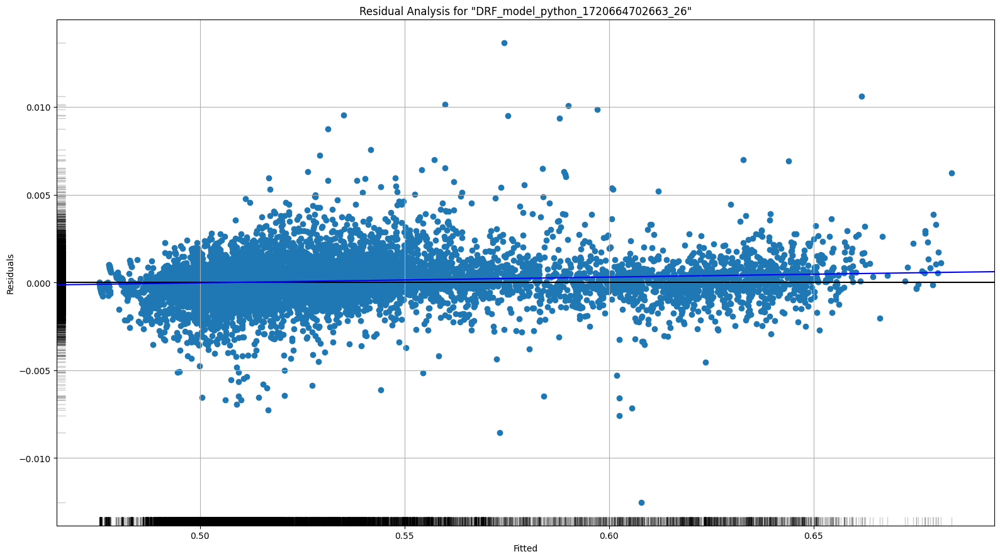

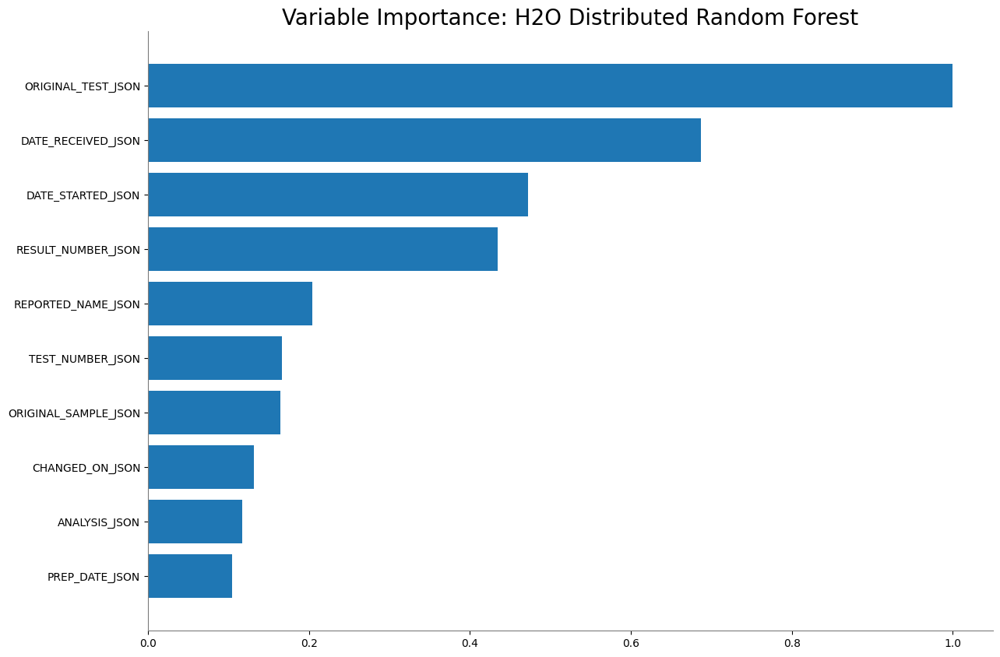

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, SIGNED_JSON, RELEASED_JSON, VARIATION_JSON, OPTIONAL_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

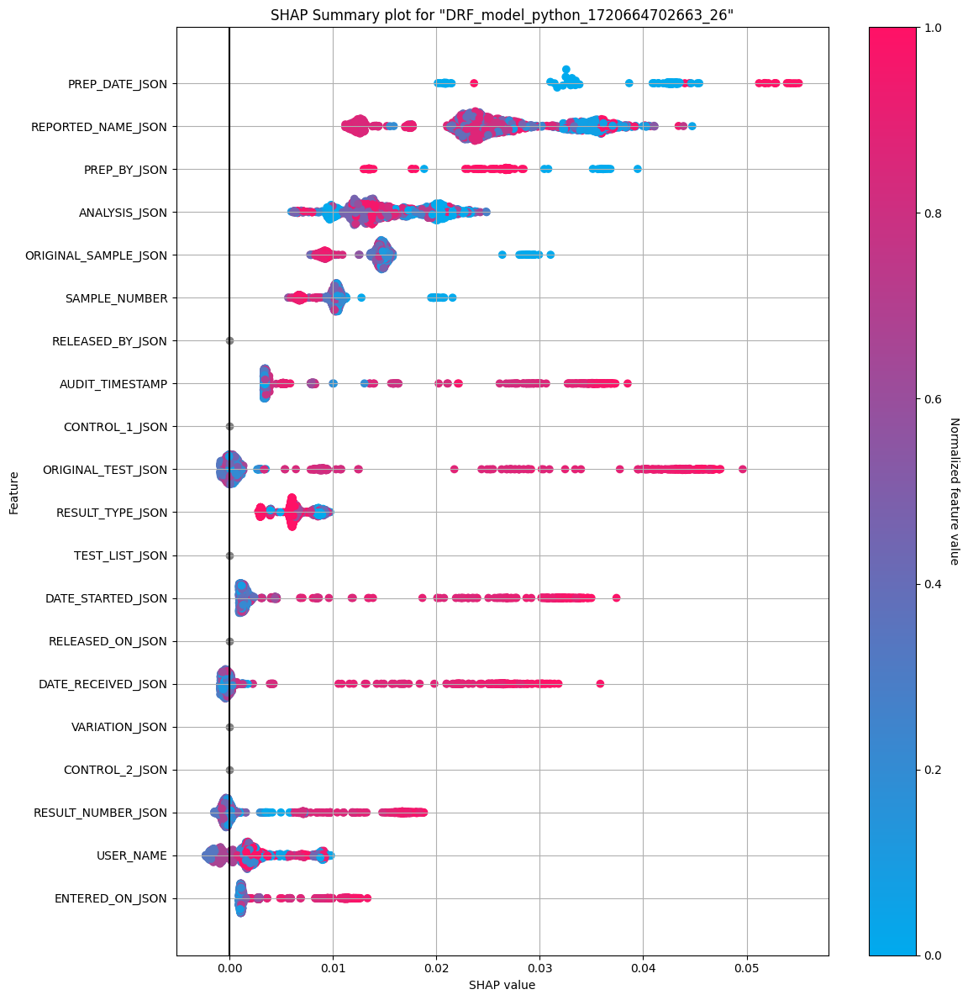

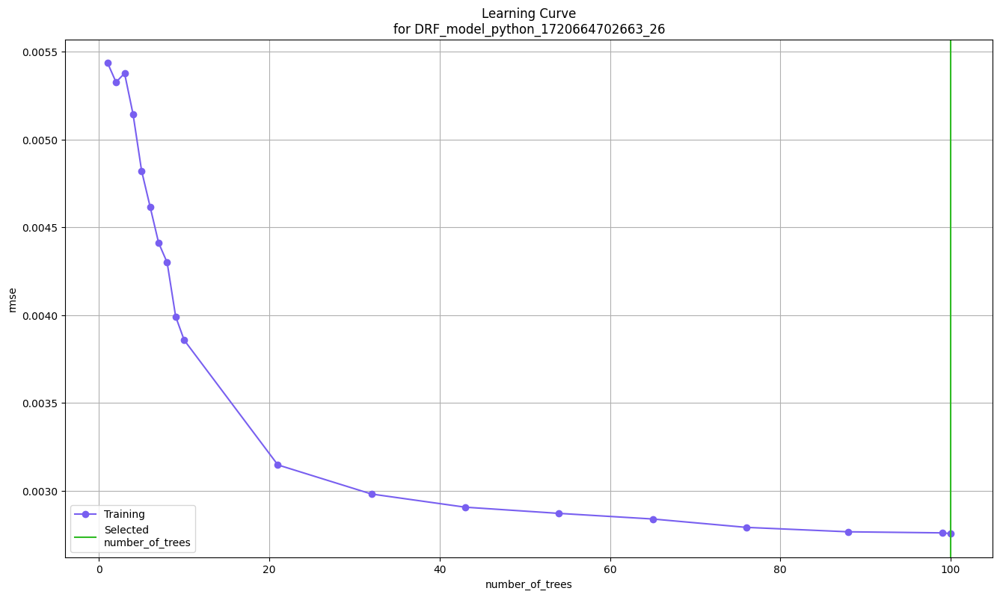

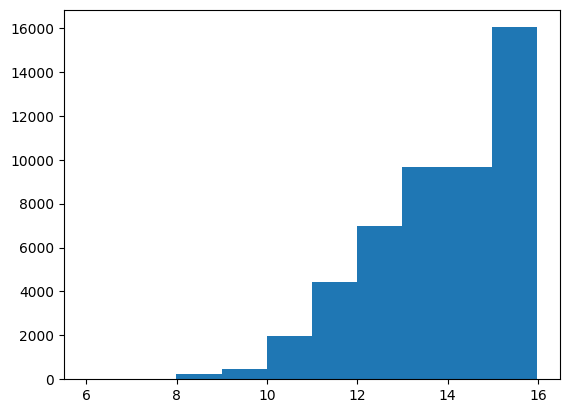

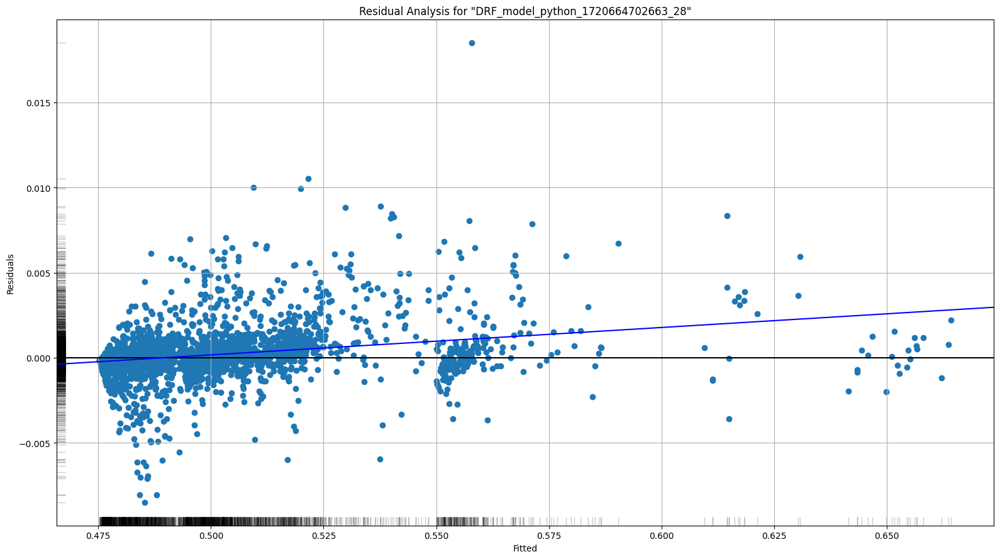

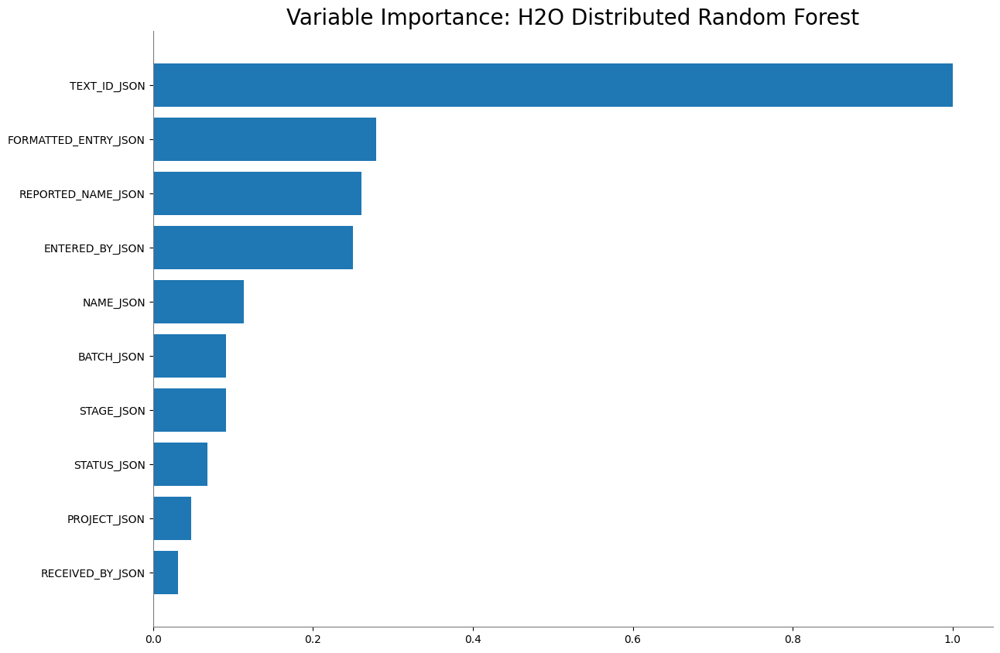

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, CONTROL_2_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, MINIMUM_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, TEST_LIST_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, INSTRUMENT_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, MAXIMUM_JSON, CONTROL_1_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, USER_ROLE, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, ENTRY_TYPE_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, CONTROL_2_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, MINIMUM_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, TEST_LIST_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, INSTRUMENT_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, MAXIMUM_JSON, CONTROL_1_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, USER_ROLE, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], Runtime

██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

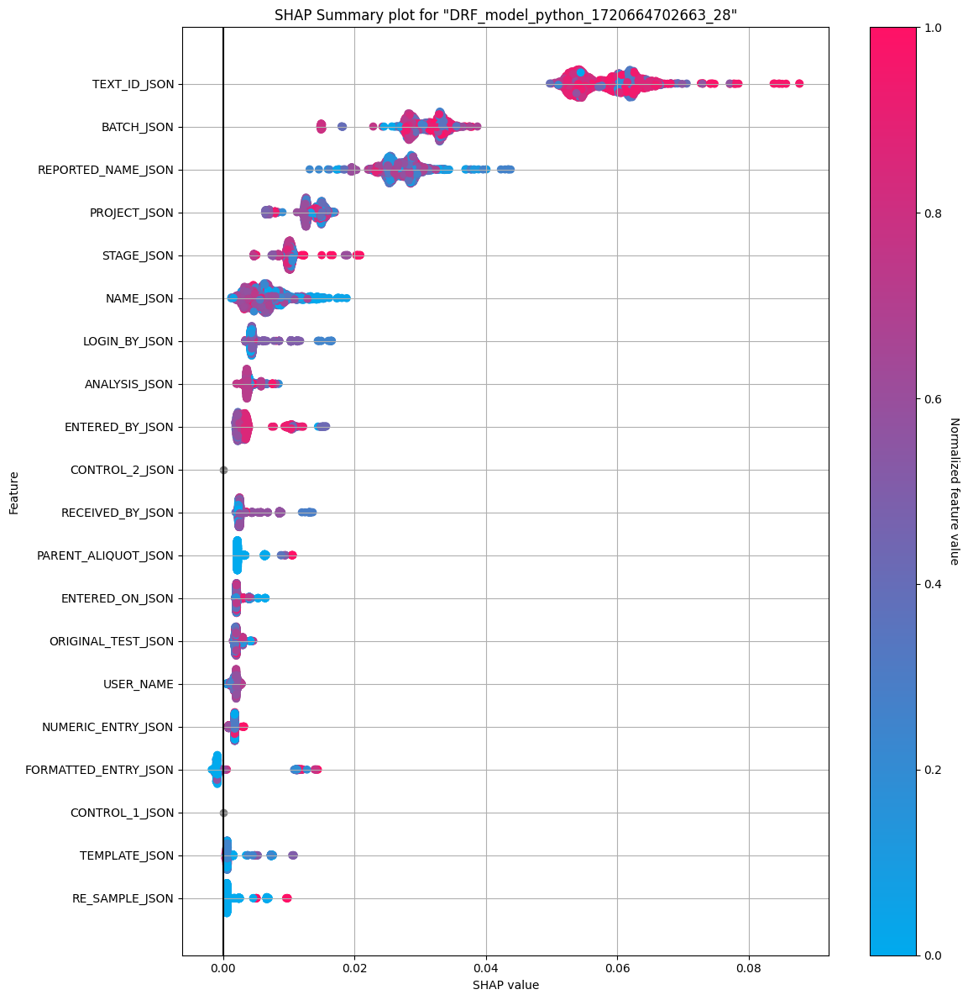

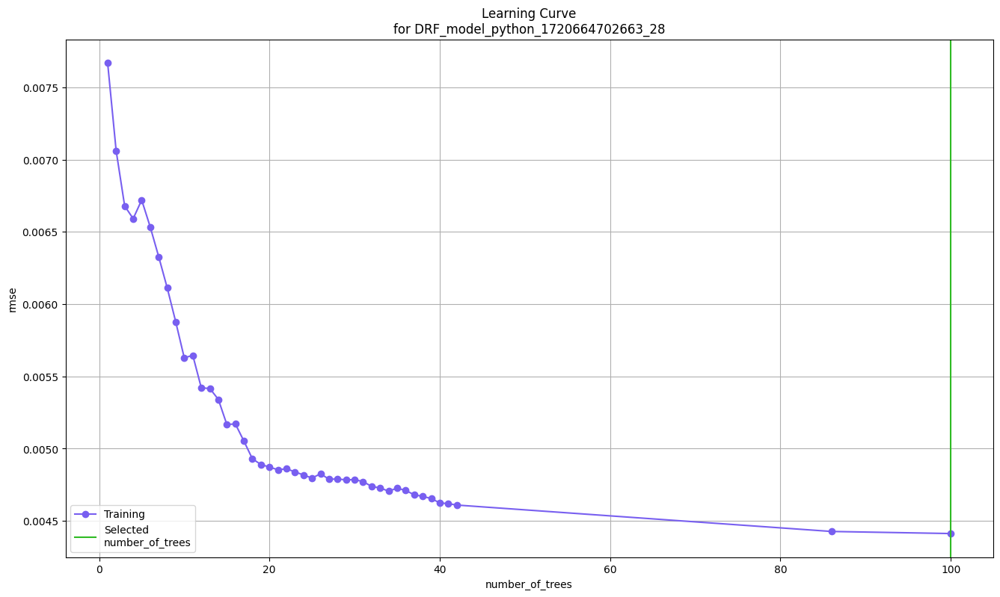

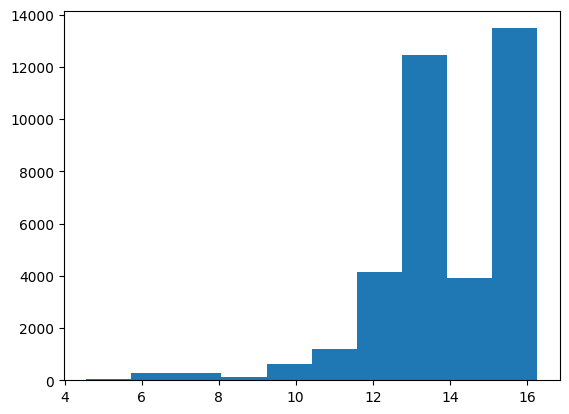

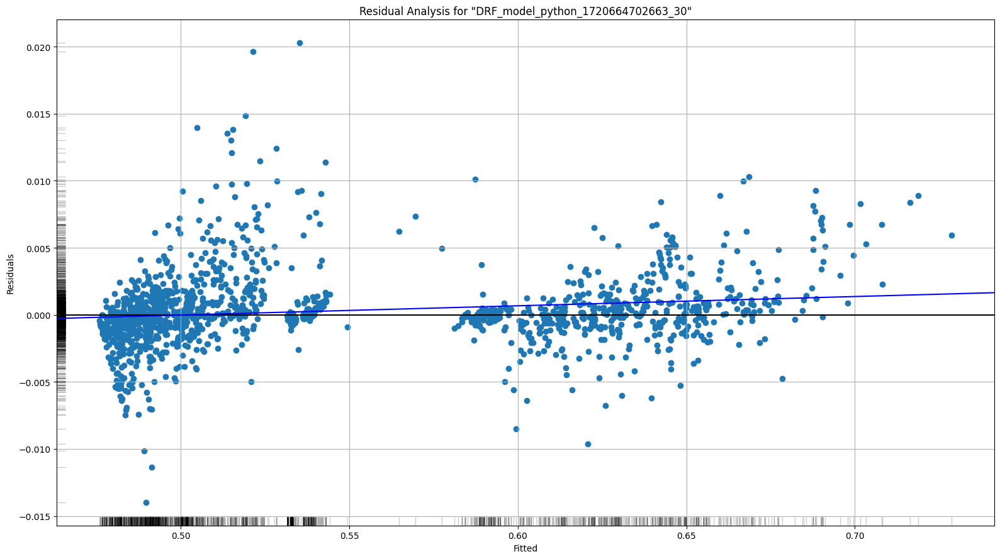

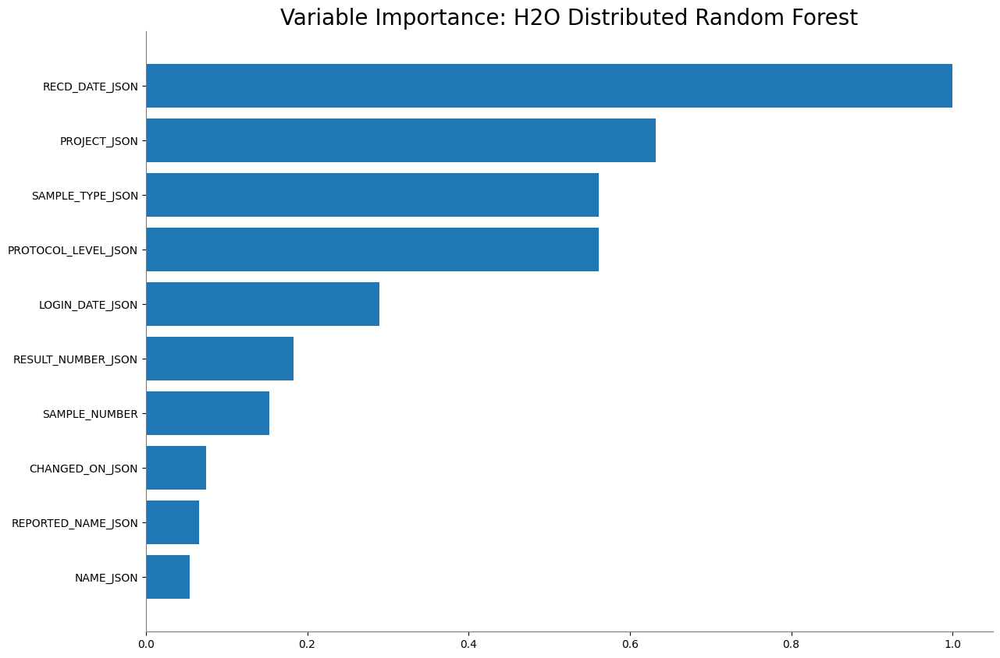

Error - Feature store file not found. Check directory.
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, RELEASED_JSON, T0083_ANOMALY, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

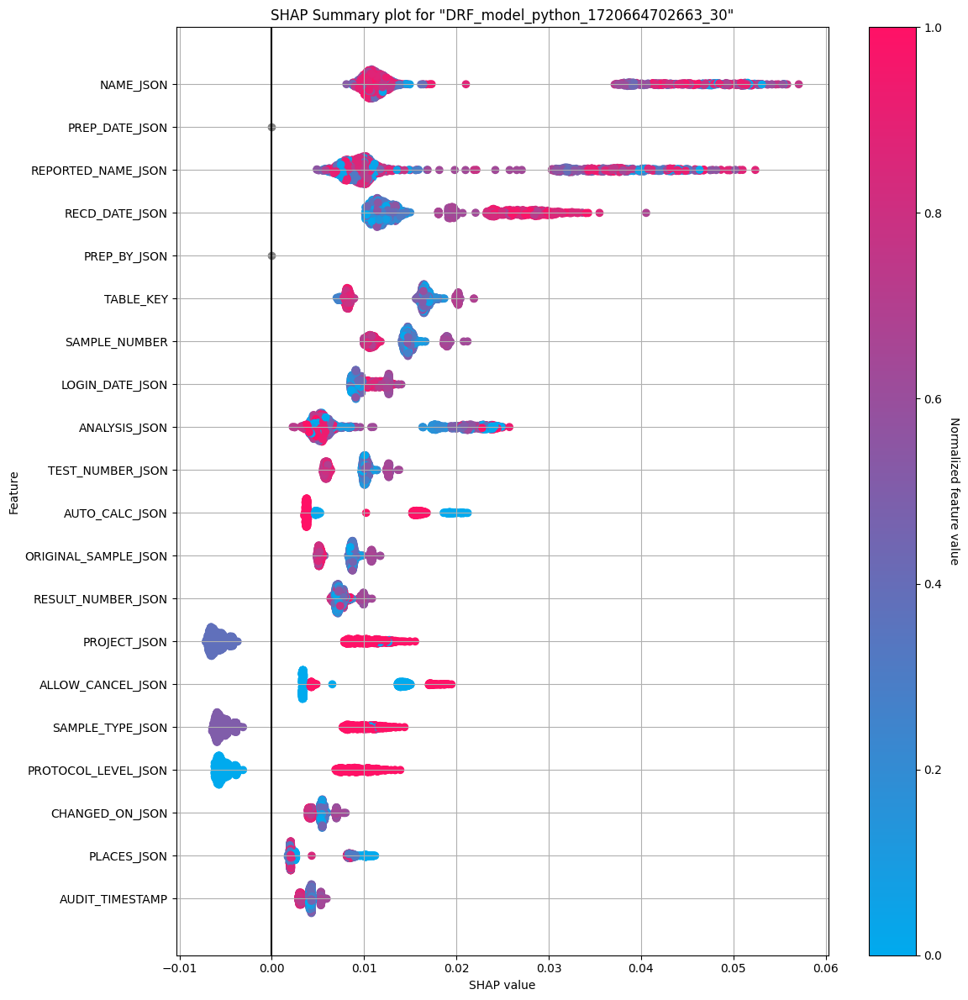

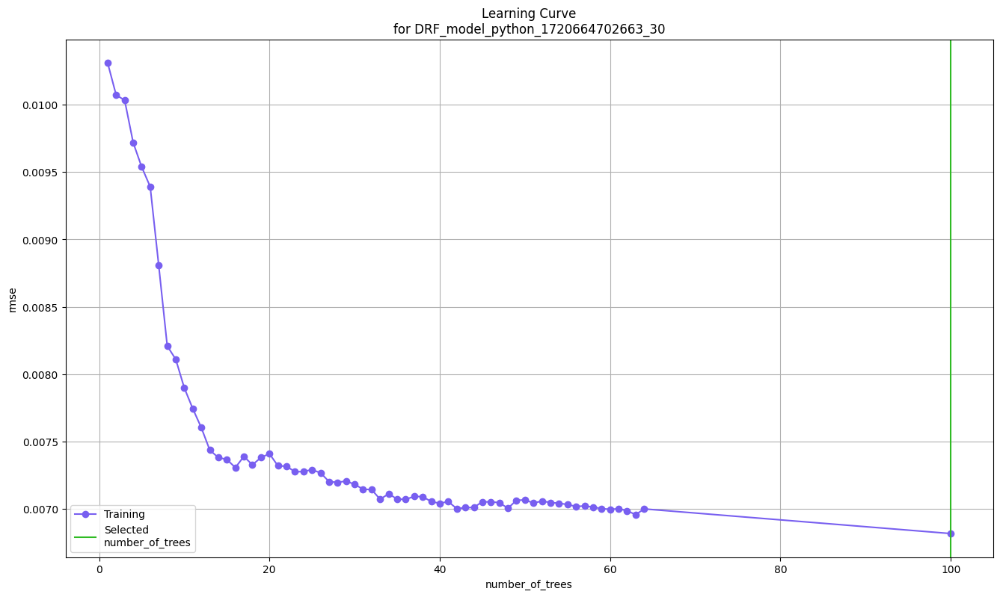

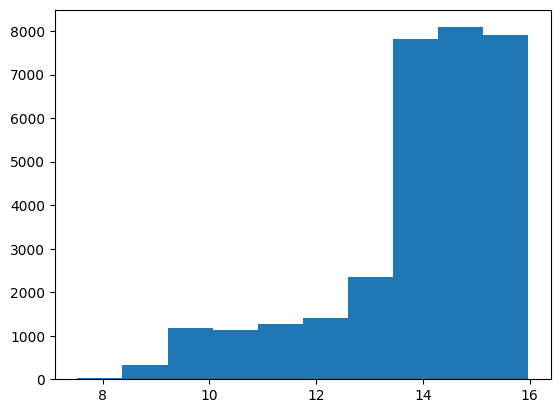

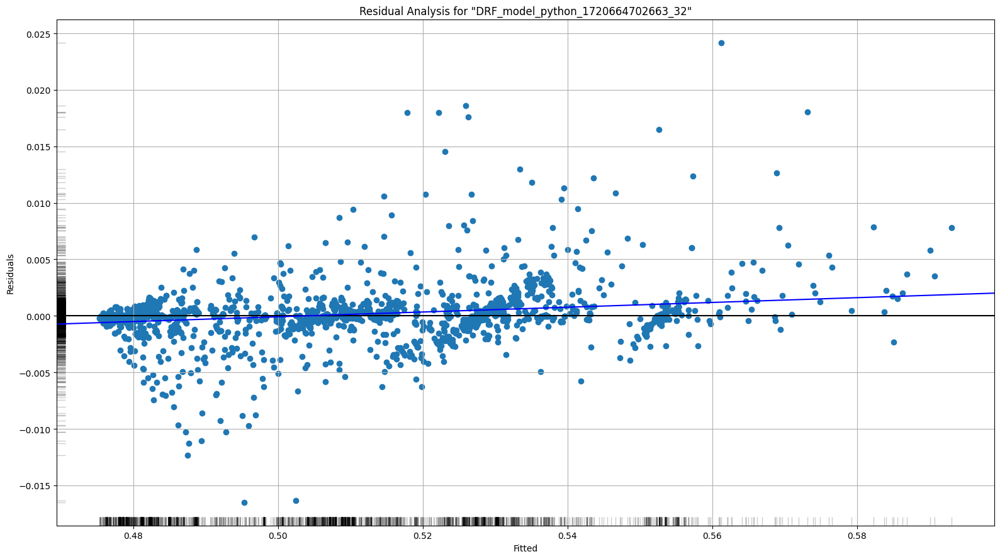

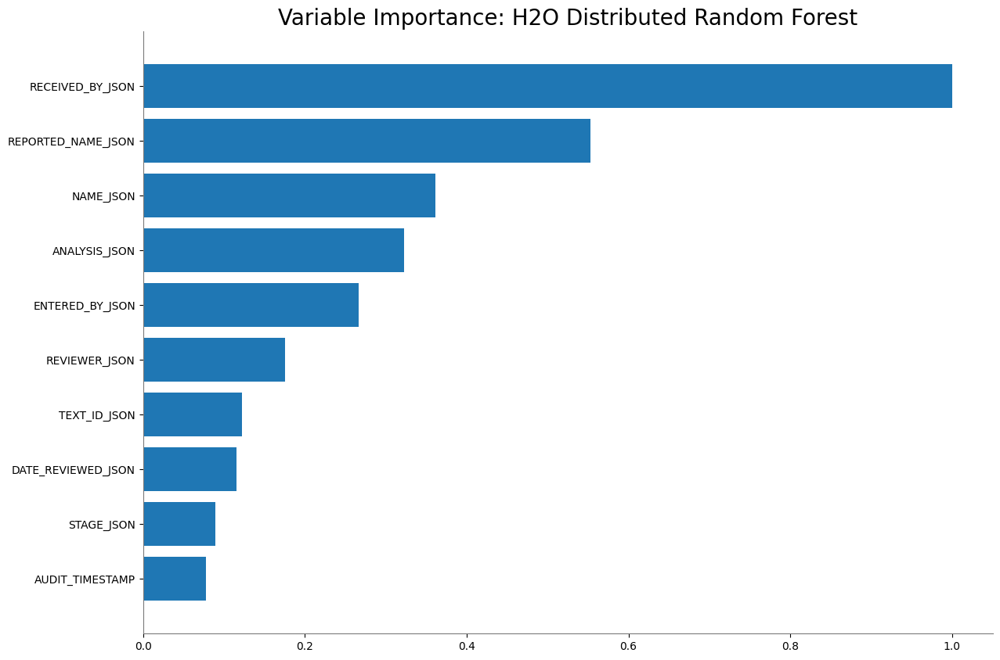

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PREP_JSON, RELEASED_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, DISPLAYED_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

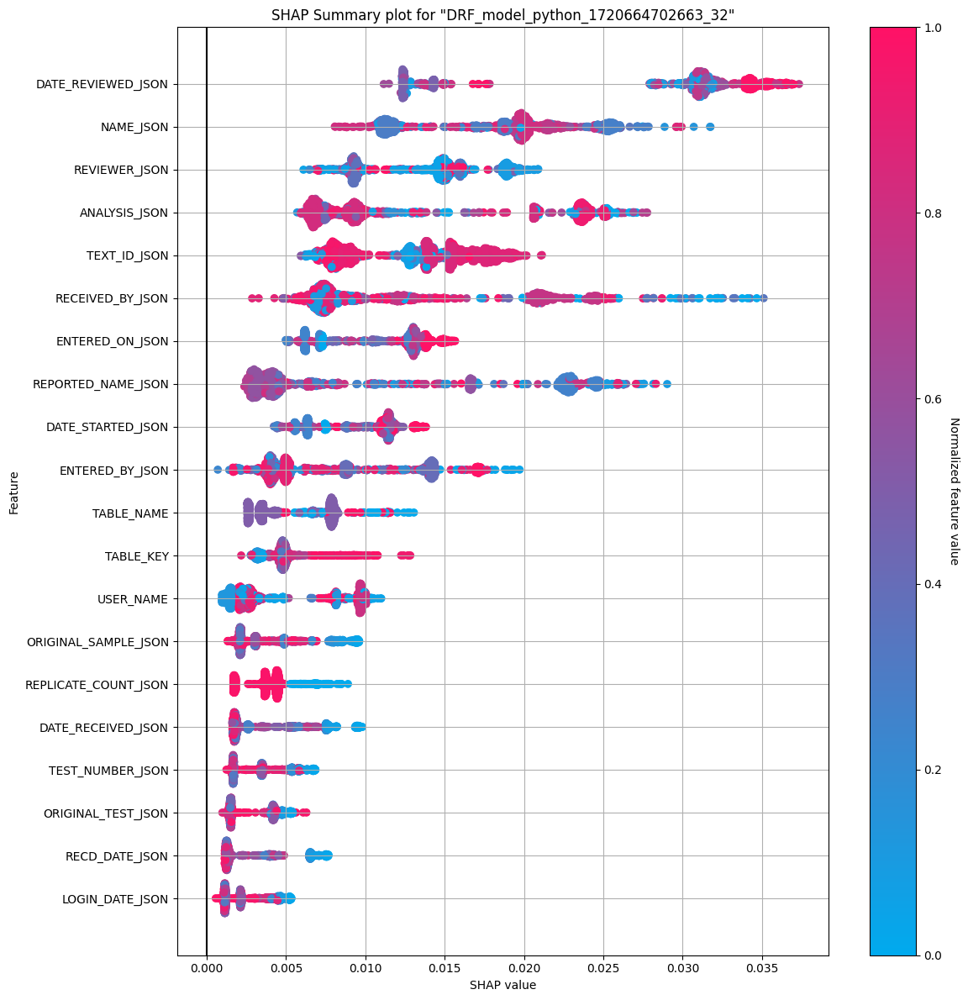

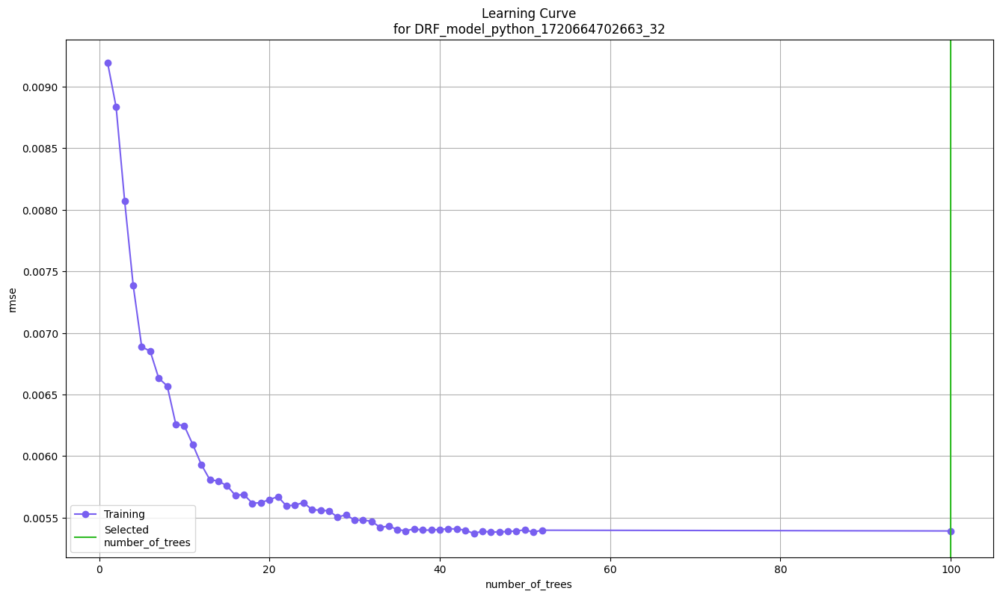

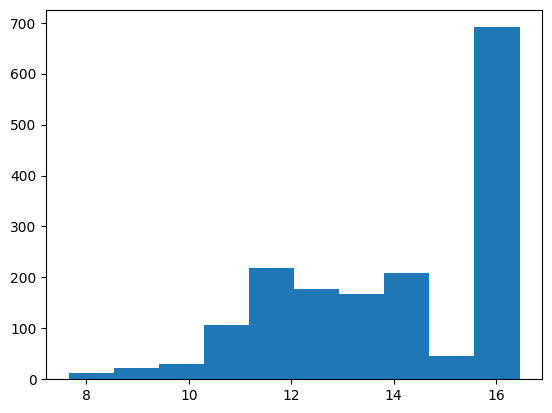

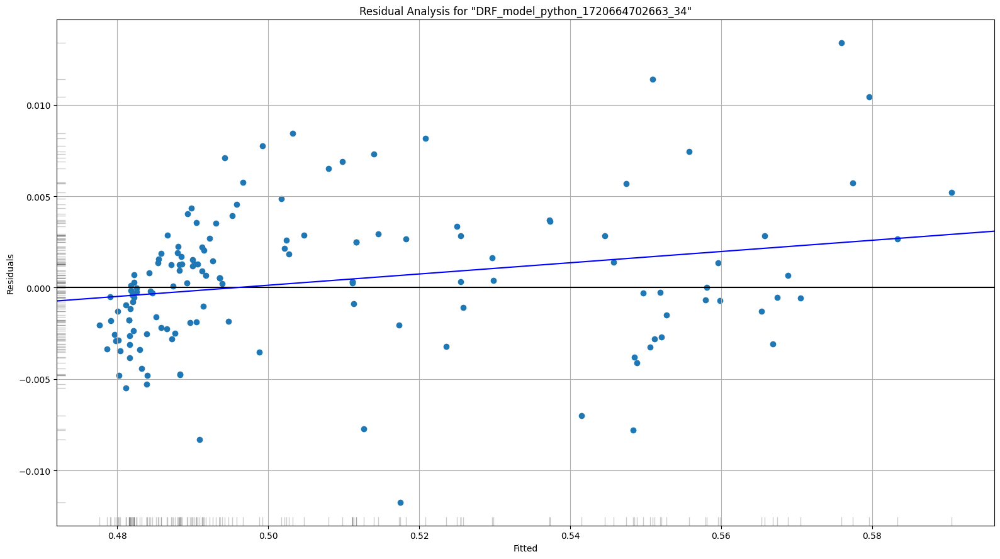

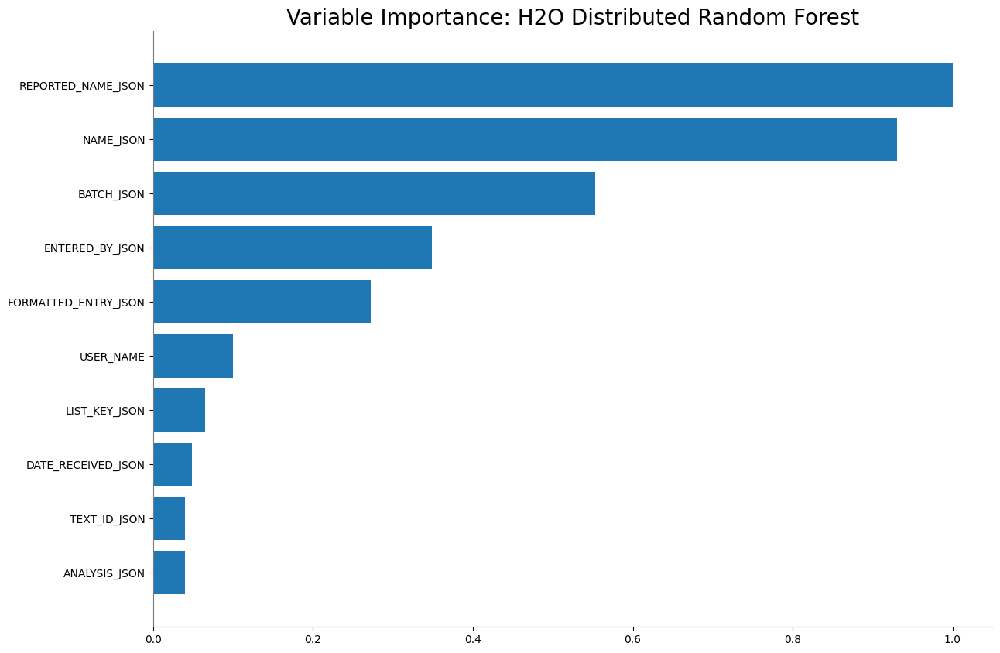

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, USER_ROLE, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, BATCH_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, MINIMUM_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, REPORTABLE_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, INSTRUMENT_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, MAXIMUM_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, USER_ROLE, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

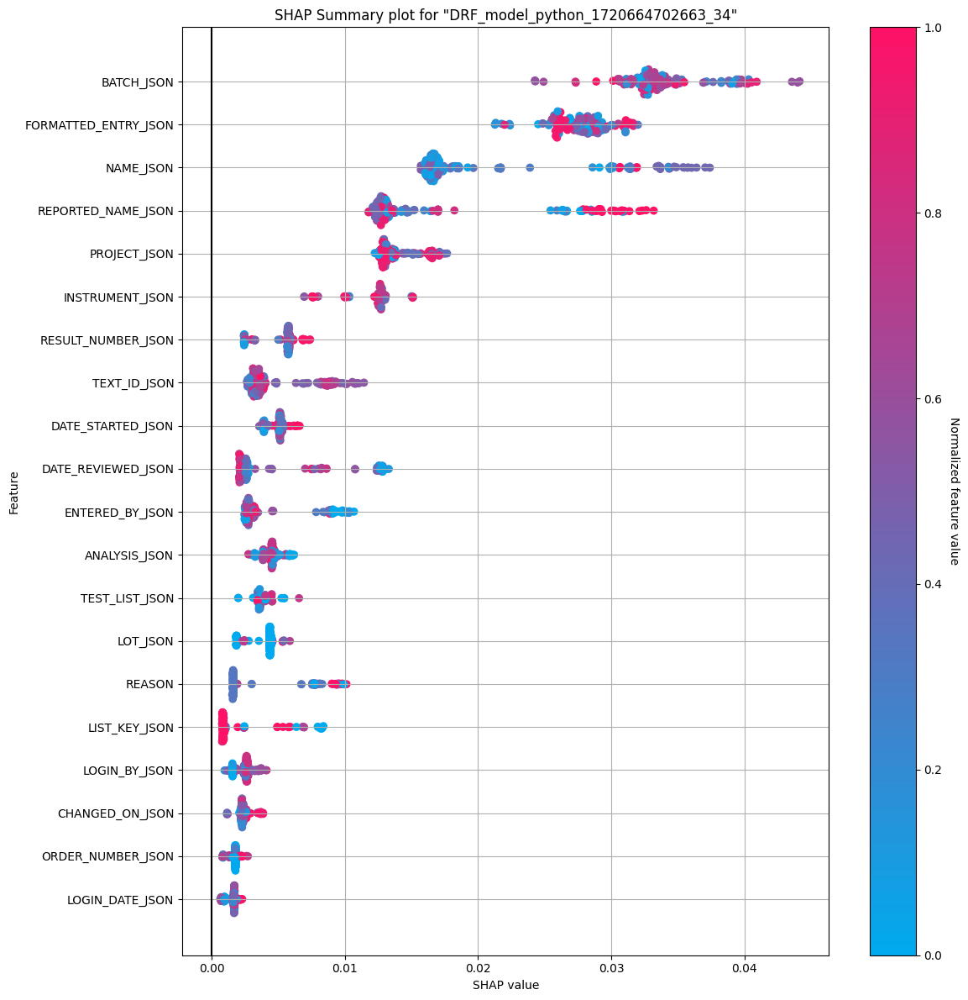

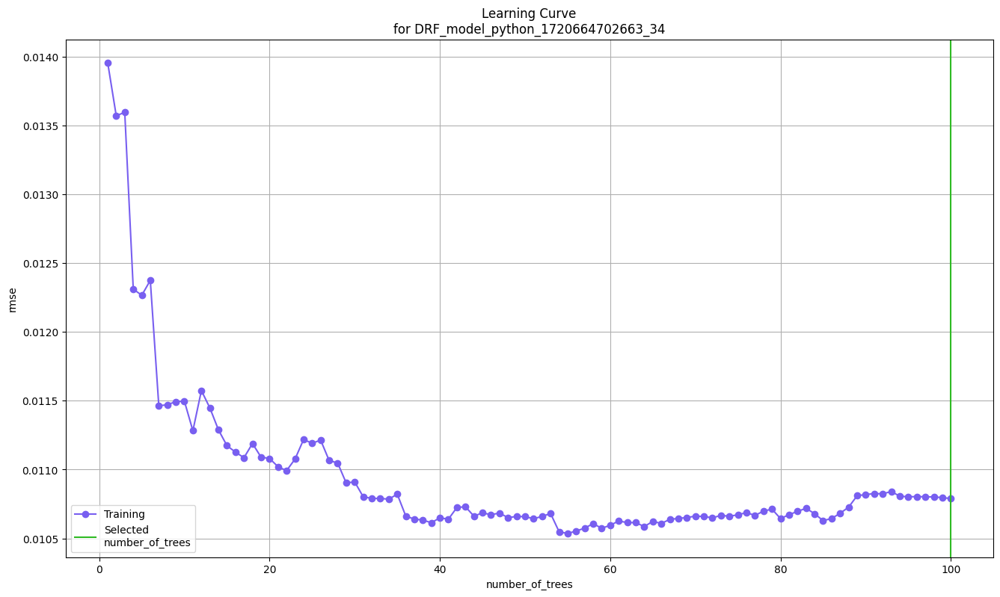

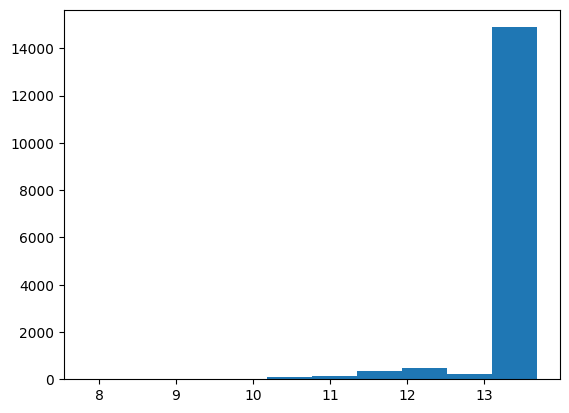

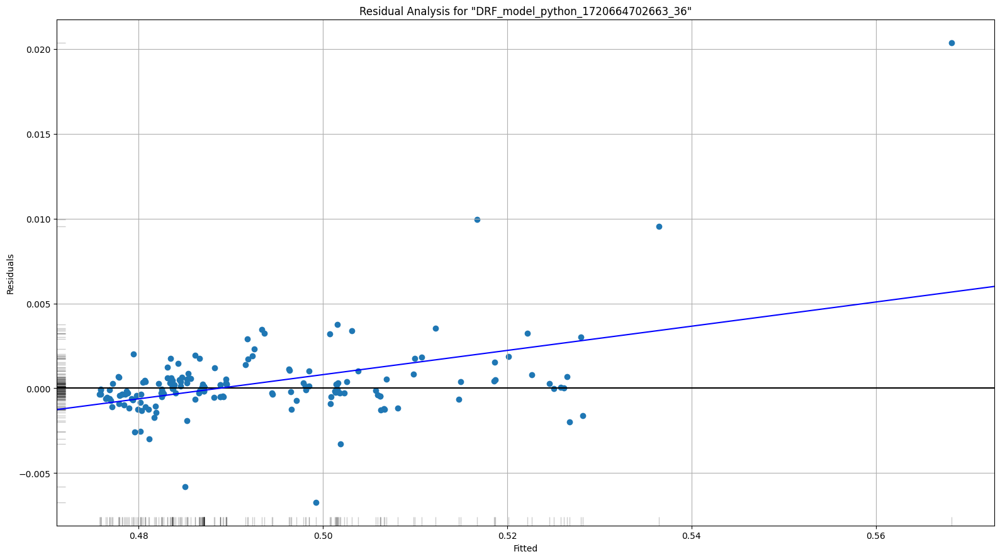

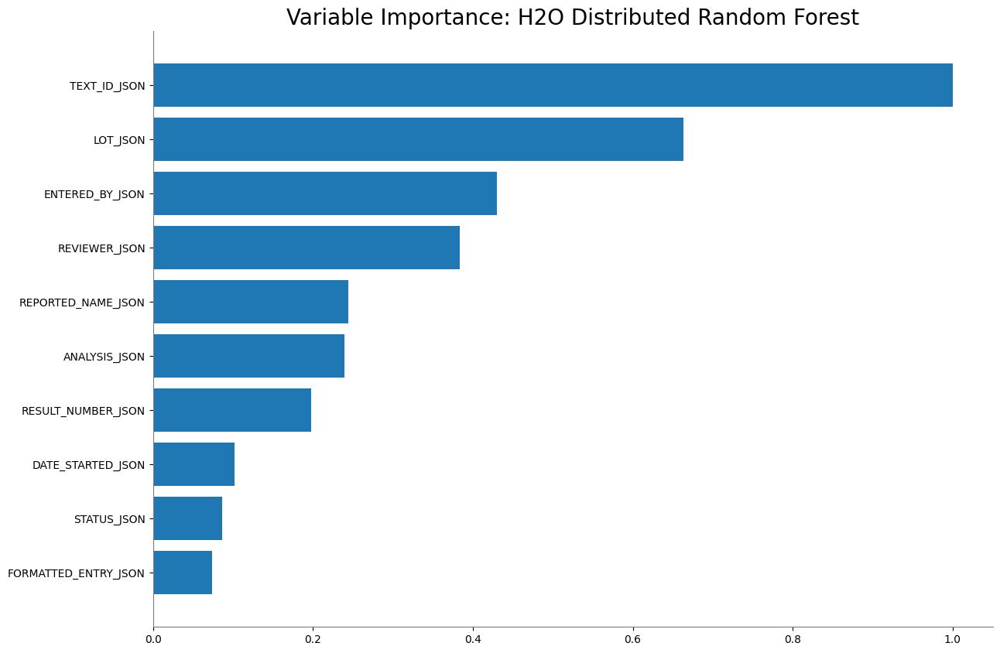

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PREP_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, PARENT_SAMPLE_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, ALLOW_CANCEL_JSON, ROUND_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, CODE_ENTERED_JSON, USER_ROLE, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, STARTED_JSON, ENTRY_TYPE_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, RE_TESTED_JSON, AUTO_CALC_JSON, RELEASED_ON_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, ALIQUOTED_TO_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, REASON, LIST_KEY_JSON, STANDARD_JSON, AUDIT_ACTION, PREP_BY_JSON, PREP_DATE_JSON, RELEASED_BY_JSON, ALLOW_OUT_JSON, ALLOW_CANCEL_JSON, REPORTED_NAME_JSON, LOT_JSON, RE_SAMPLE_JSON, HAS_FLAGS_JSON, AUDIT_TYPE, RESULT_TYPE_JSON, PARENT_TEST_JSON, PRODUCT_VERSION_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, ALIQUOT_JSON, STD_REAG_SAMPLE_JSON, BATCH_ORIGINAL_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, RELEASED_JSON, TEMPLATE_JSON, OPTIONAL_JSON, STAGE_JSON, HAS_ATTRIBUTES_JSON, CONTROL_2_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, COMPOSITE_JSON, PLACES_JSON, IN_CAL_JSON, ANALYSIS_JSON, CHILD_

██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

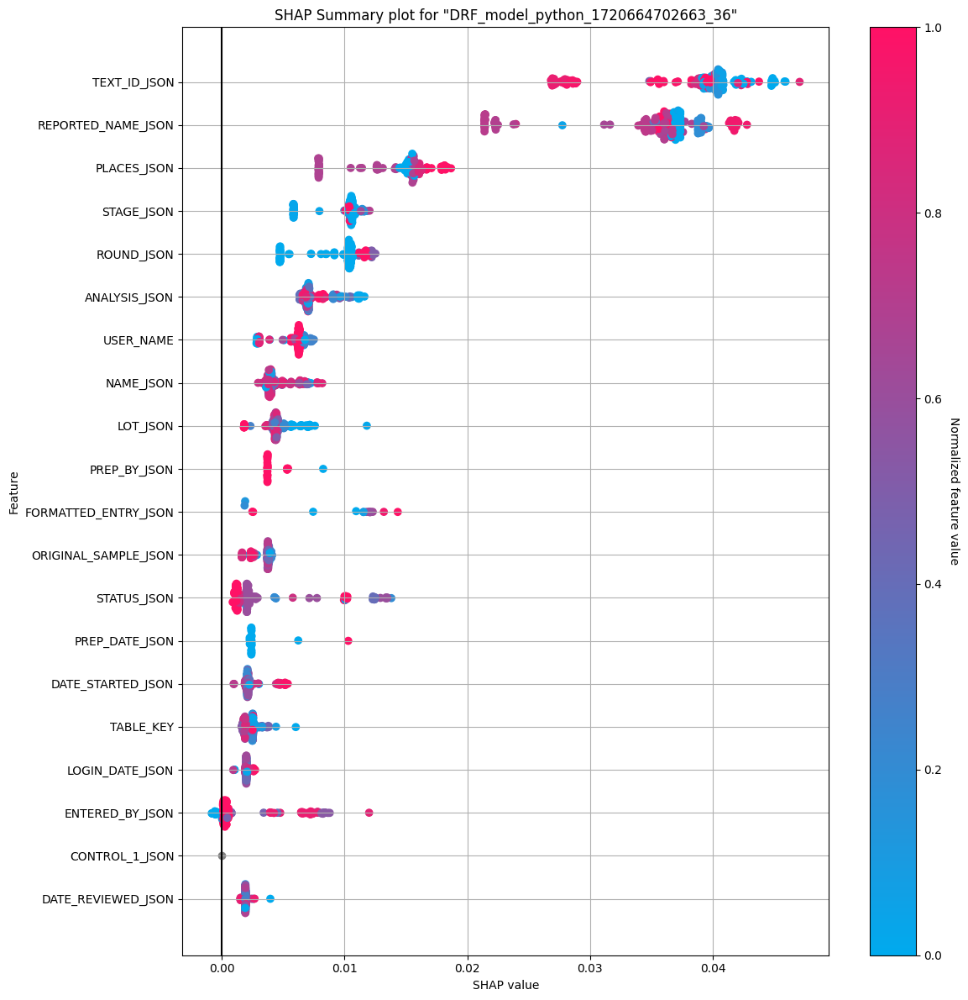

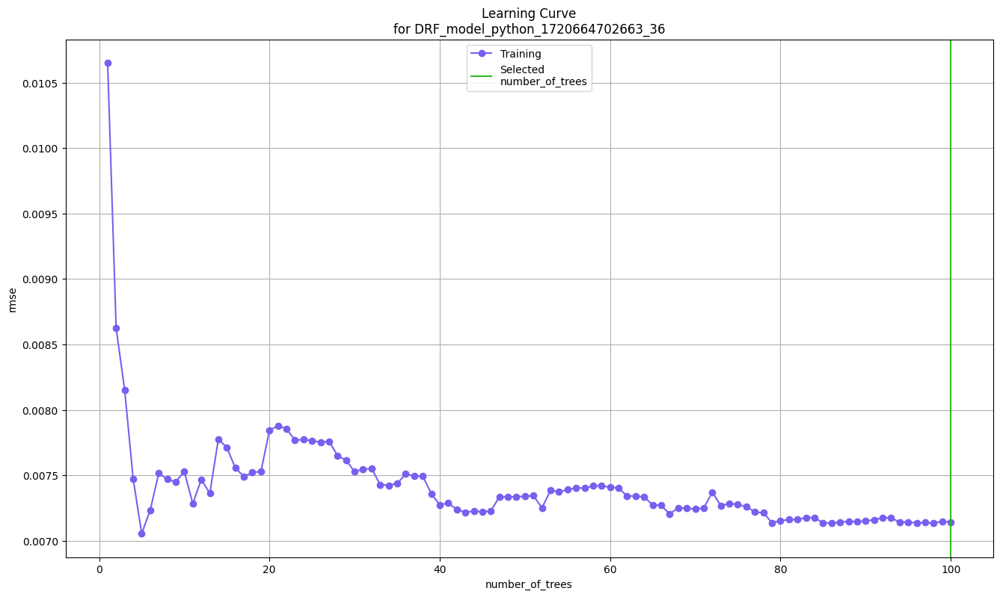

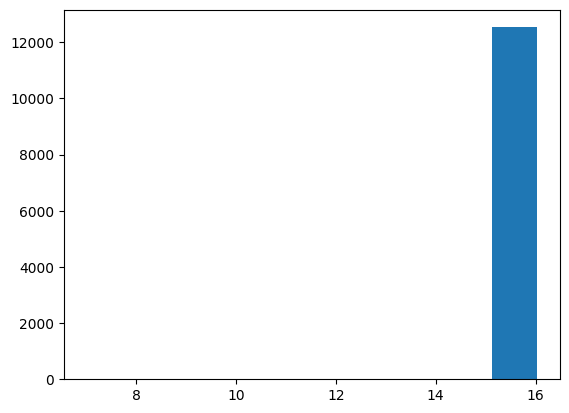

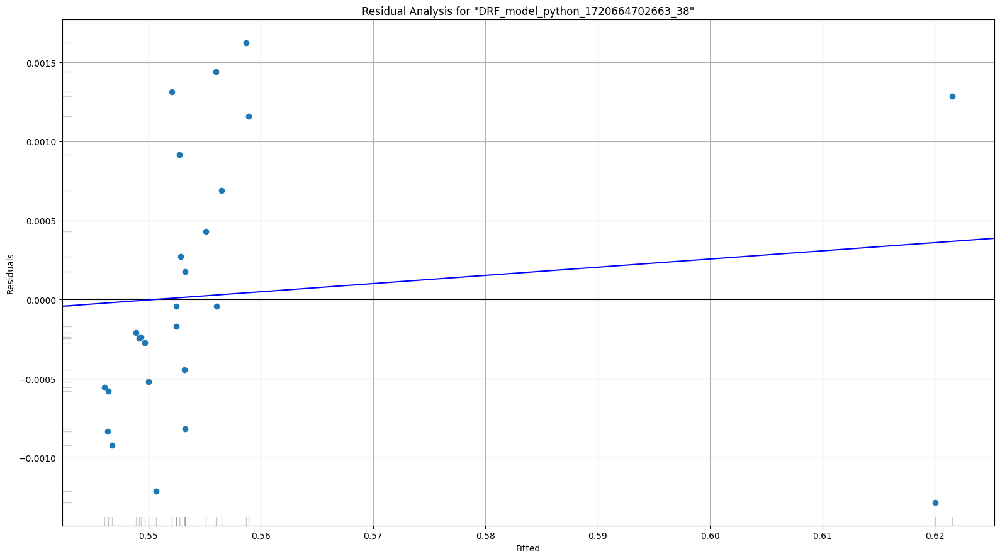

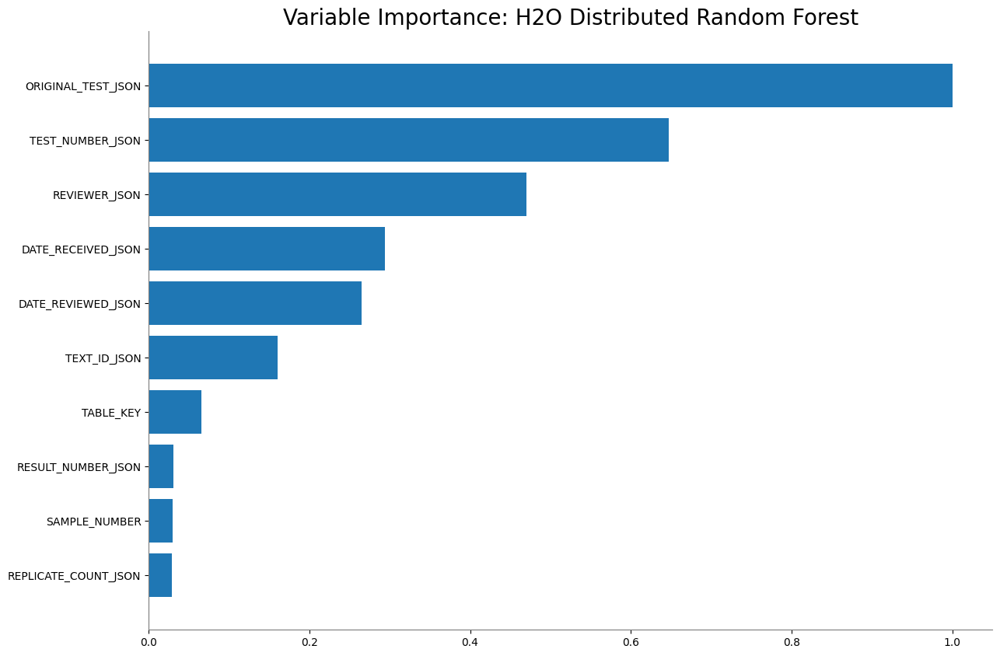

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, STARTED_JSON, RELEASED_JSON, T0083_ANOMALY, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, COMPOSITE_JSON, ALIQUOTED_TO_JSON, MODIFIED_RESULTS_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, ANALYSIS_COUNT_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, STARTED_JSON, RELEASED_JSON, T0083_ANOMALY, PARENT_SAMPLE_JSON, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, MODIFIED_RESULTS_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, USES_INSTRUMENT_JSON, DISPLAYED_JSON, ANALYSIS_COUNT_JSON, REPLICATE_TEST_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, REPLICATE_COUNT_JSON, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)


██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

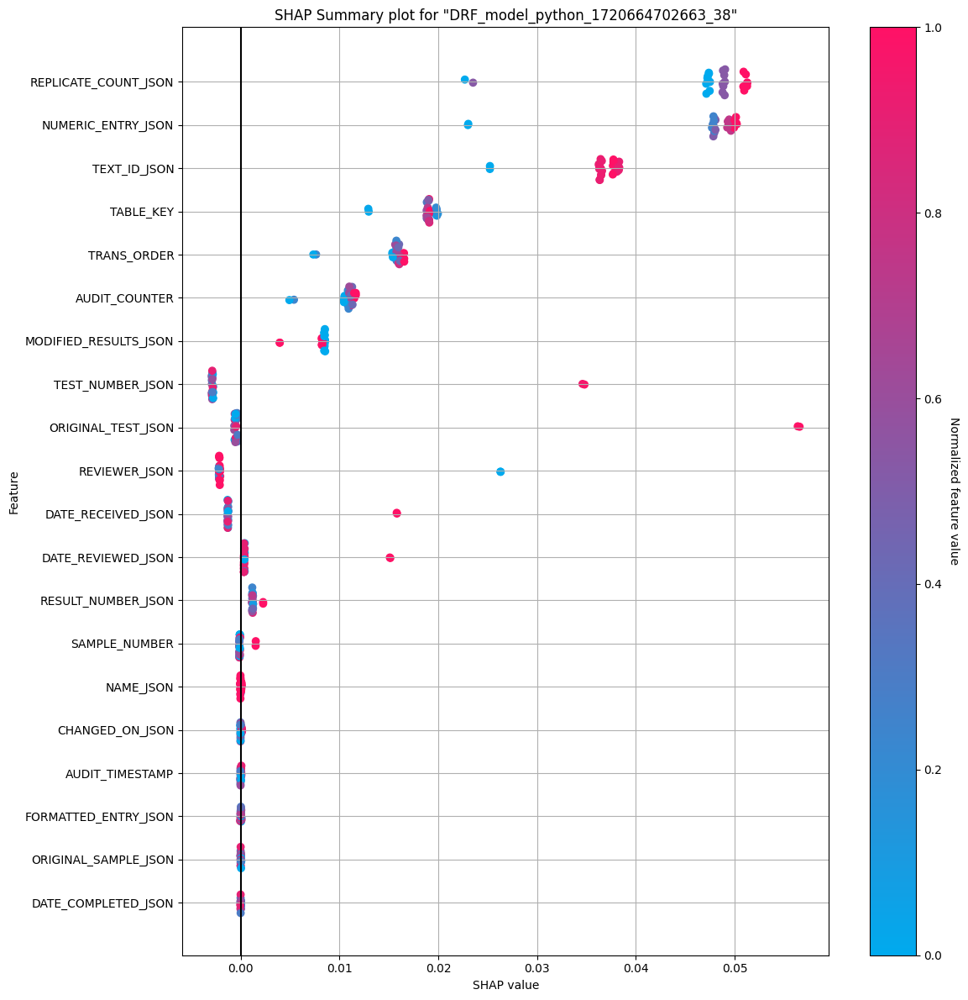

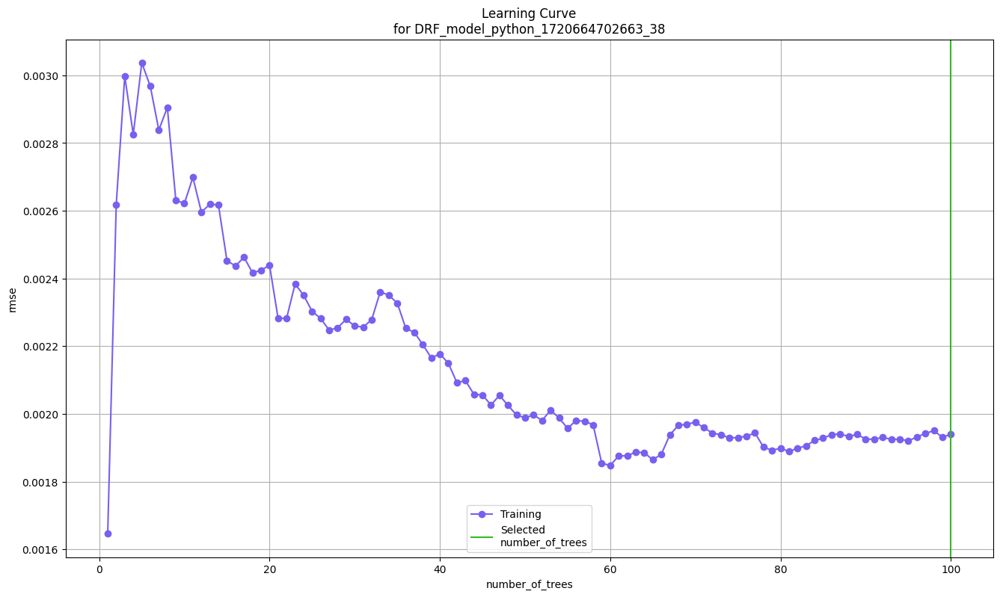

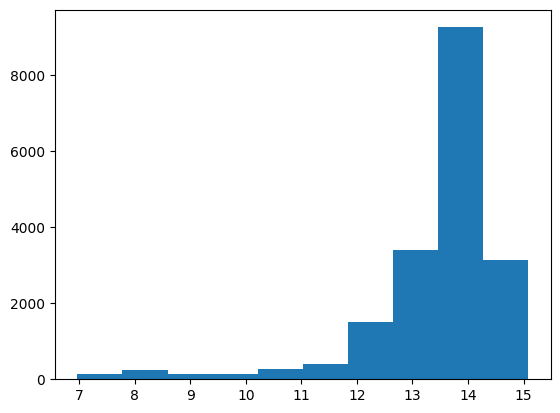

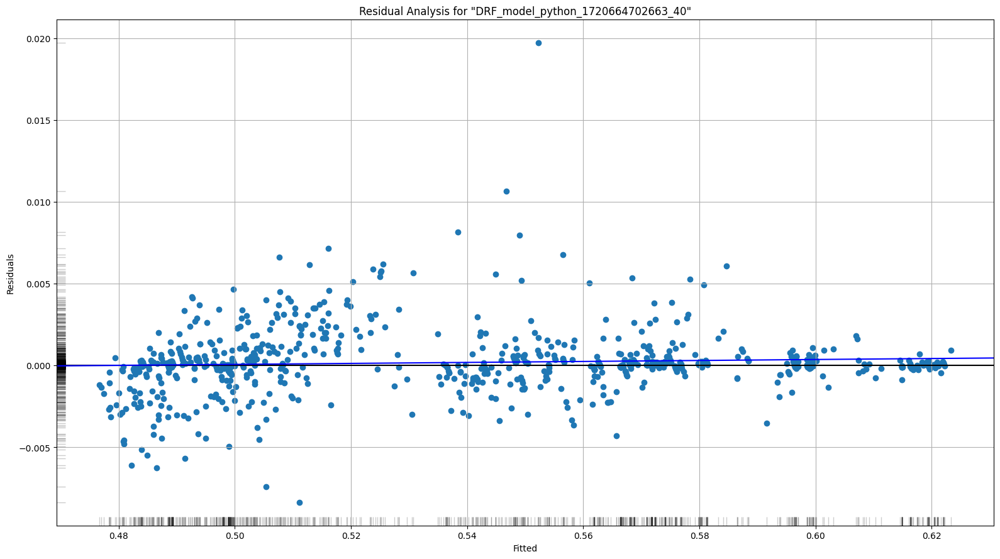

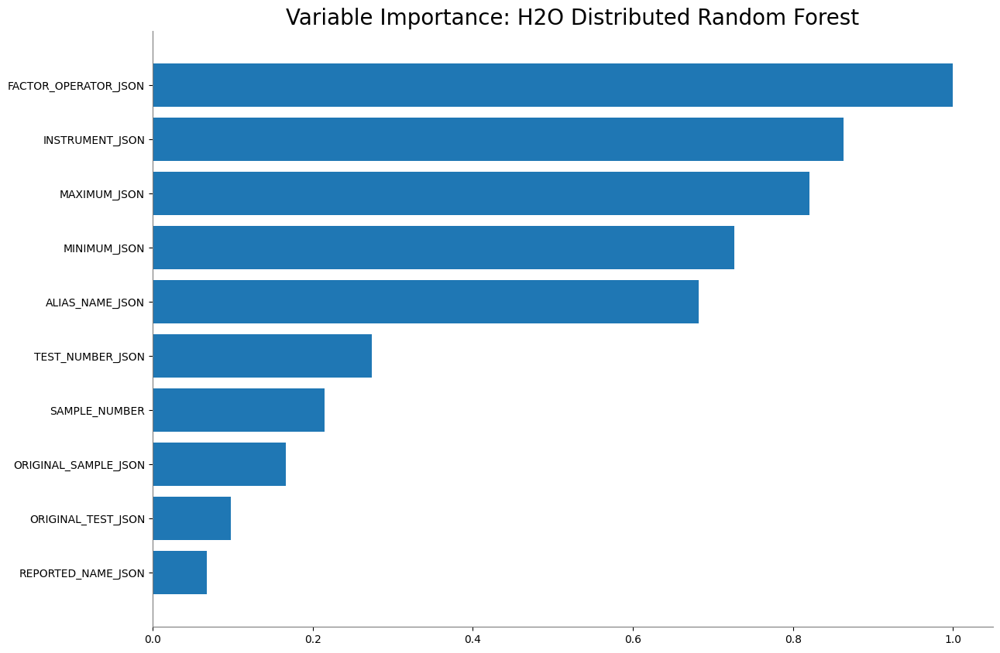

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, SIGNED_JSON, STARTED_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, T0083_ANOMALY, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, MODIFIED_RESULTS_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, ANALYSIS_COUNT_JSON, REPLICATE_TEST_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, REPLICATE_COUNT_JSON, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["message"], RuntimeWarning)

██████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
drf Model Build progress: |

c:\DSE\Python\Lib\site-packages\h2o\estimators\estimator_base.py:192: RuntimeWarning: Dropping bad and constant columns: [BATCH_PARENT_TEST_JSON, ALIAS_NAME_JSON, PRIMARY_IN_SPEC_JSON, PREP_JSON, SIGNED_JSON, STARTED_JSON, RELEASED_JSON, VARIATION_JSON, FACTOR_OPERATOR_JSON, T0083_ANOMALY, RE_TESTED_JSON, HAS_ATTRIBUTES_JSON, RELEASED_ON_JSON, GROUP_NAME_JSON, CROSS_SAMPLE_JSON, PARTIAL_SPEC_JSON, RECORD_SIGNED, COMPOSITE_JSON, ALIQUOTED_TO_JSON, MODIFIED_RESULTS_JSON, PARENT_COMPOSITE_JSON, ON_WORKSHEET_JSON, IN_CAL_JSON, STANDARD_JSON, AUDIT_ACTION, CHILD_OUT_SPEC_JSON, IN_CONTROL_JSON, PREP_BY_JSON, DISPLAYED_JSON, PREP_DATE_JSON, ANALYSIS_COUNT_JSON, REPLICATE_TEST_JSON, RELEASED_BY_JSON, USES_CODES_JSON, ALLOW_OUT_JSON, HAS_FLAGS_JSON, RESOLVE_REQD_JSON, AUDIT_TYPE, PARENT_TEST_JSON, INVESTIGATED_JSON, PARENT_ALIQUOT_JSON, CHARGE_ENTRY_JSON, IN_SPEC_JSON, CODE_ENTERED_JSON, STD_REAG_SAMPLE_JSON, SOURCE_DB, REPLICATE_COUNT_JSON, BATCH_ORIGINAL_TEST_JSON]
  warnings.warn(mesg["messa

██████████████████████████████████████████████████████| (done) 100%


<Figure size 640x480 with 0 Axes>

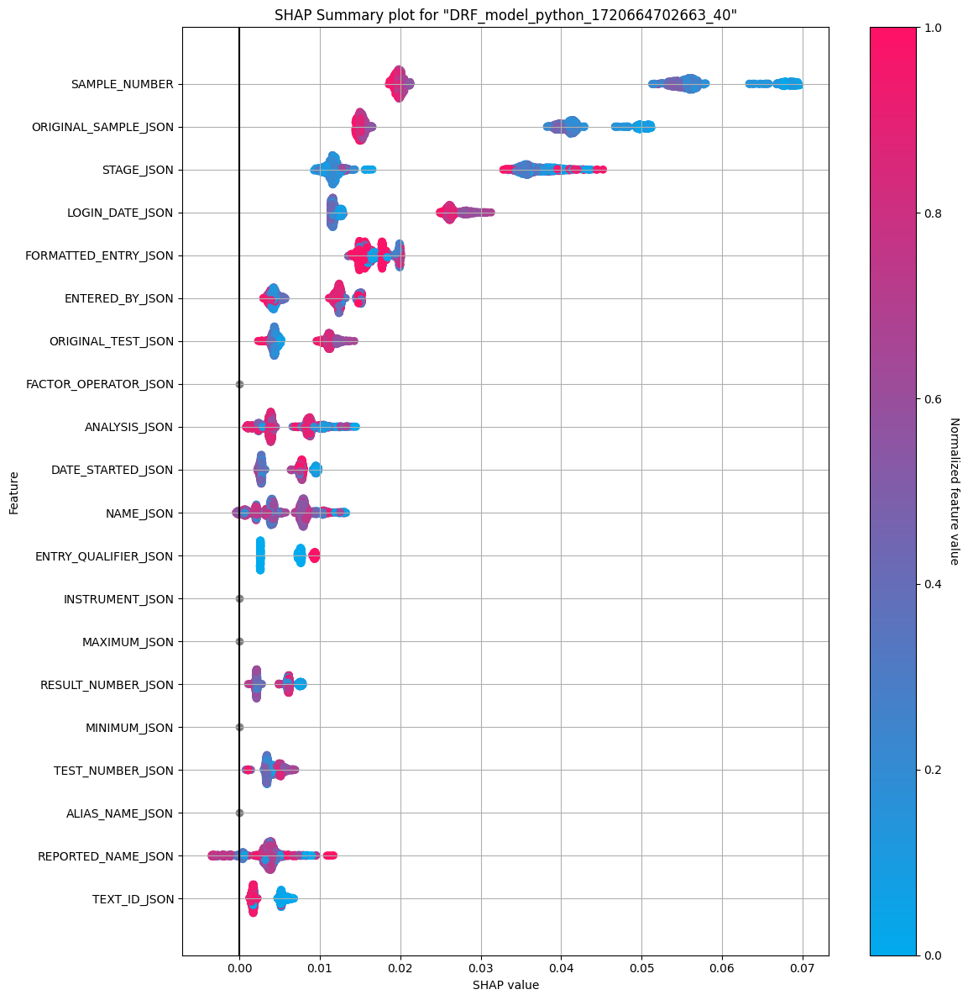

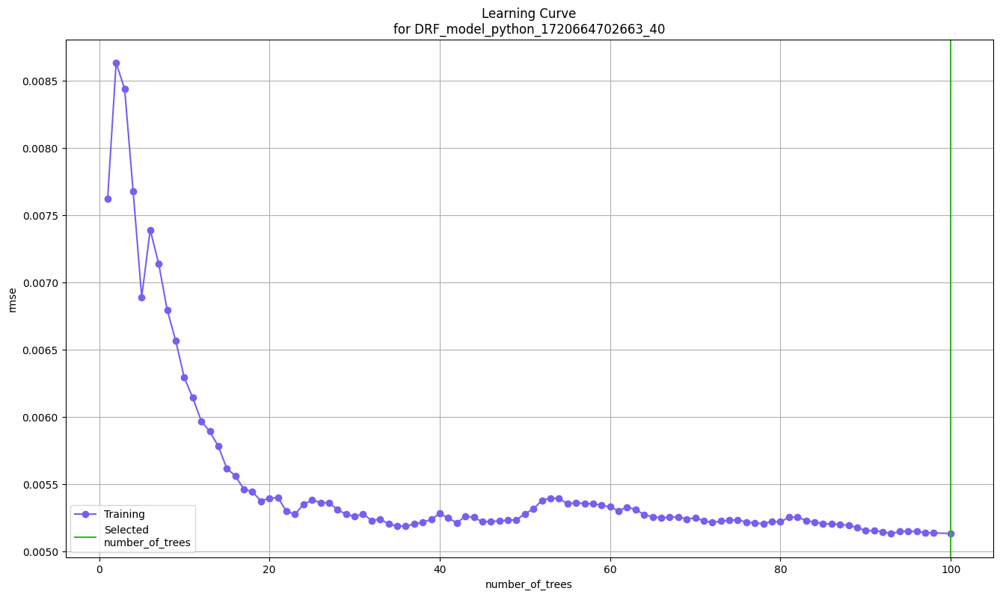

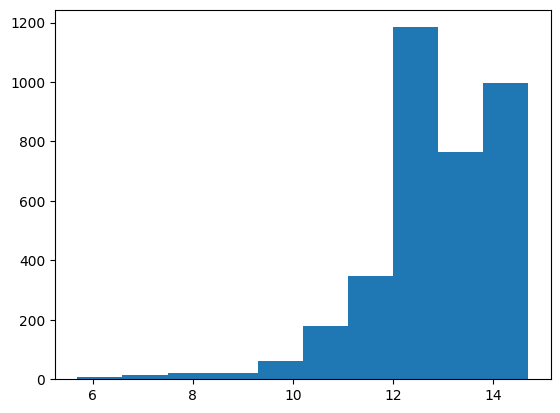

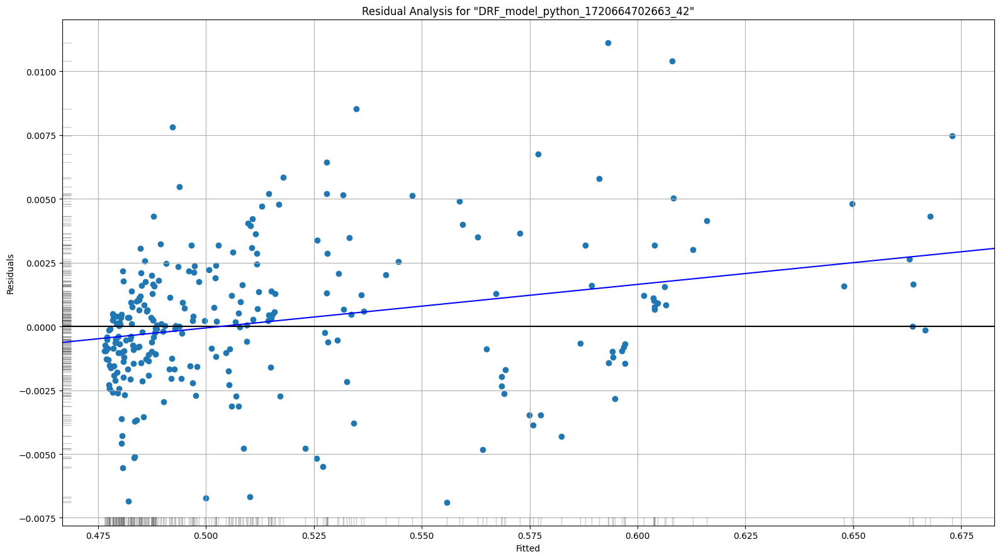

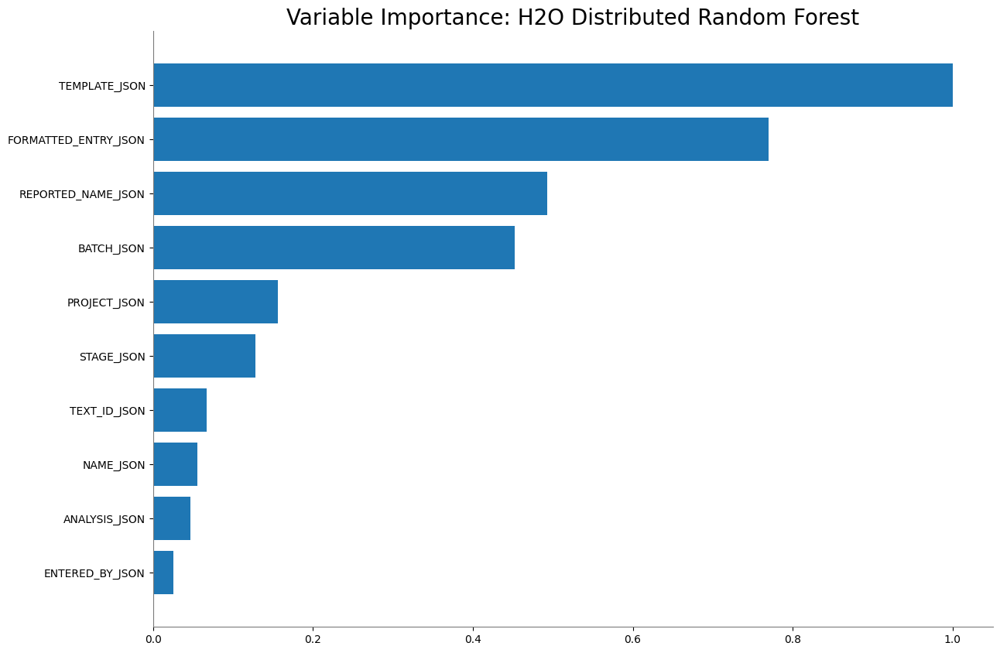

Error - Feature store file not found. Check directory.
Error - Feature store file not found. Check directory.


<Figure size 640x480 with 0 Axes>

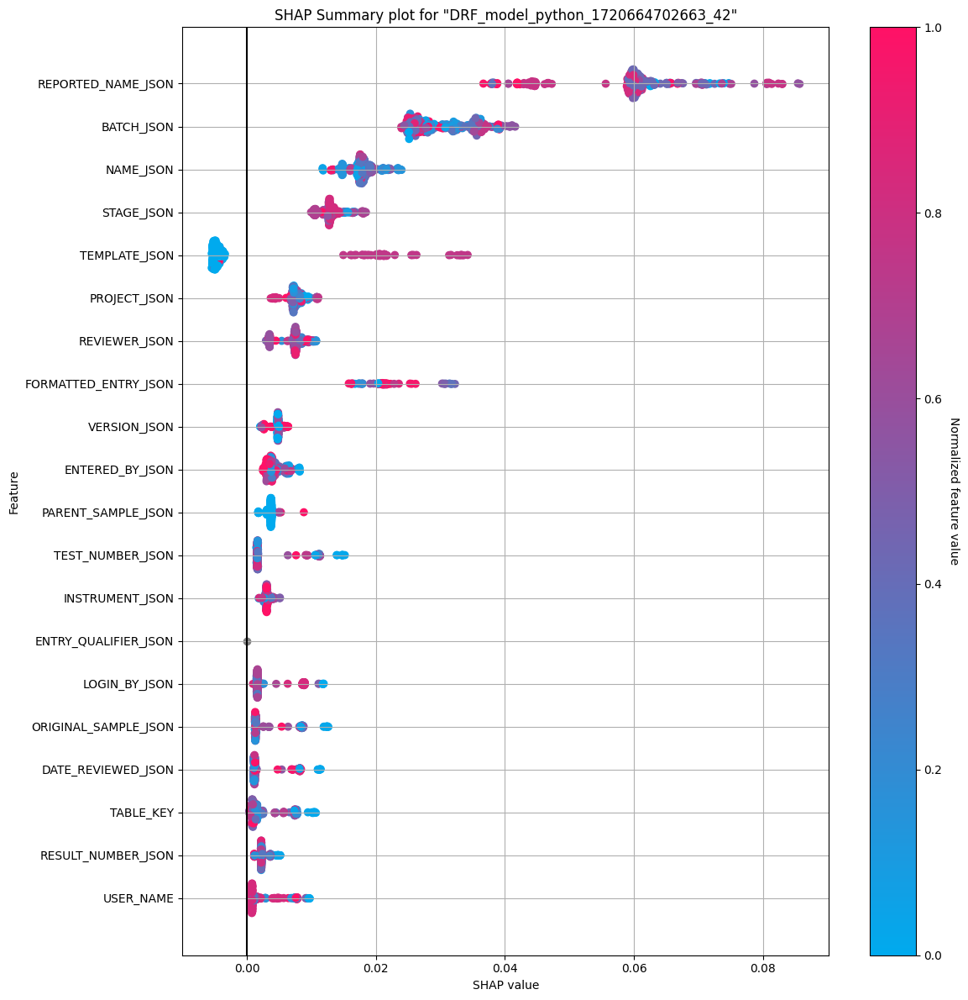

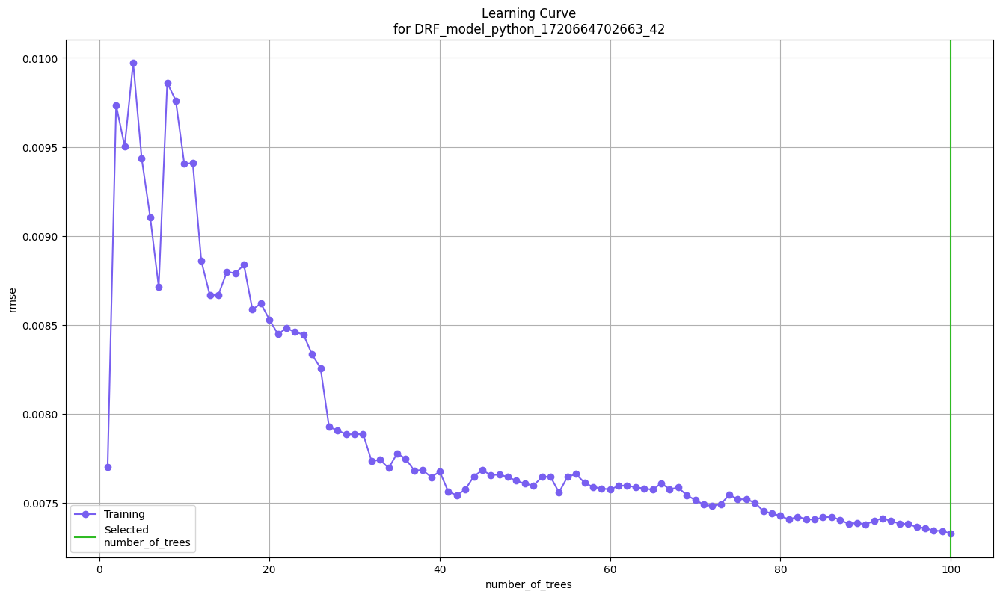

In [4]:
# Start an MLflow run
mlflow.set_experiment("audit_type_based_testing") #Default
algoType = "h2o_eif_single"

with mlflow.start_run(run_name=algoType, nested=True) as greatgrandparent_run:
    for FilterType in FilterTypeList: 
        with mlflow.start_run(run_name=f"Audit_Type_{FilterType}", nested=True) as grandparent_run:
            for customer in customerList:
                with mlflow.start_run(run_name=f"Run_{customer}", nested=True) as parent_run:
                    filepath = Path(f'C:/MLAR_DATA/T0001/FS_audit_type_table_name/{FilterType}/FS_audit_type_table_name_{FilterType}_{customer}.parquet')
                    if filepath.is_file()==True:
                        parquet = pd.read_parquet(filepath)
                        df = parquet.drop(['T0083','T0083_SEVERITY'],axis=1) #reduce some of customer specific ID-related features already removed 'LABEL_ID','LABEL_MASK','TEXT_ID_JSON'
                        df = df.astype(str).replace('nan',np.nan)
                        df.dropna(how='all', axis=1, inplace=True)
                        features = list(df.columns.values) #drop(columns=['T0083', 'T0083_SEVERITY']) <- Already not present 
                        h2oFrame = h2o.H2OFrame(python_obj=df)
                                                
                        #mlflow.log_param("num_trees",config.numTrees)
                        
                        eif_model = H2OExtendedIsolationForestEstimator(ntrees=config.numTrees, ignore_const_cols=True, seed=1234)
                        
                        eif_model.train(x=features,training_frame=h2oFrame)

                        predictions = eif_model.predict(h2oFrame)
                        df = predictions["mean_length"]
                                               
                        
                        # Predict anomalies and generate histogram
                        predictedH2oFrame = eif_model.predict(h2oFrame)
                        predictedDF = predictedH2oFrame.as_data_frame(use_pandas=True, use_multi_thread=True)
                        figure, axis = plt.subplots()
                        axis.hist(predictedDF["mean_length"])
                        mlflow.log_figure(figure, "mean_length.png")       

                        # Set mean_length value for unsupervised
                        # Combine the scores with the original data
                        anomalies = h2oFrame[predictedH2oFrame["mean_length"] < 11.0]
                        finalH2oFrame = eif_model.predict(anomalies).cbind(anomalies)
                        
                        #Export Dataset
                        mlflow.log_table(predictedDF,"predictedDF.json")

                        with mlflow.start_run(run_name=f"Explain_model", nested=True) as child_run:
                            #Train explaination model
                            DRF_model = H2ORandomForestEstimator(ntrees=config.numTrees)
                            DRF_model.train(x=features, y="anomaly_score", training_frame=finalH2oFrame) 
                           
                            # DRF_model.explain(predictedH2oFrame) equivalent minus pdp, ice plots
                            ra_plot = DRF_model.residual_analysis_plot(finalH2oFrame).figure()
                            mlflow.log_figure(ra_plot, "residual_analysis_plot.png")
                            vi_plot = DRF_model.varimp_plot().figure()
                            mlflow.log_figure(vi_plot, "variable_importance_plot.png")
                            ss_plot = DRF_model.shap_summary_plot(finalH2oFrame).figure()
                            mlflow.log_figure(ss_plot, "shap_summary_plot.png") 
                            lc_plot = DRF_model.learning_curve_plot().figure()
                            mlflow.log_figure(lc_plot, "learning_curve_plot.png")      

                             #predictContribution = DRF_model.predict_contributions(predictedH2oFrame)            

                    else:
                        print("Error - Feature store file not found. Check directory.")        
              

# Residual Analysis

> Residual Analysis plots the fitted values vs residuals on a test dataset. Ideally, residuals should be randomly distributed. Patterns in this plot can indicate potential problems with the model selection, e.g., using simpler model than necessary, not accounting for heteroscedasticity, autocorrelation, etc. Note that if you see "striped" lines of residuals, that is an artifact of having an integer valued (vs a real valued) response variable.

c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'SAMPLE_NUMBER': substituting in a column of NaN
  warnings.warn(w)
c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'AUDIT_TIMESTAMP': substituting in a column of NaN
  warnings.warn(w)
c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'AUDIT_COUNTER': substituting in a column of NaN
  warnings.warn(w)
c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'TRANS_ORDER': substituting in a column of NaN
  warnings.warn(w)
c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'TABLE_NAME': substituting in a column of NaN
  warnings.warn(w)
c:\DSE\Python\Lib\site-packages\h2o\job.py:81: UserWarning: Test/Validation dataset is missing column 'TABLE_KEY': substituting in a column of NaN
  warn

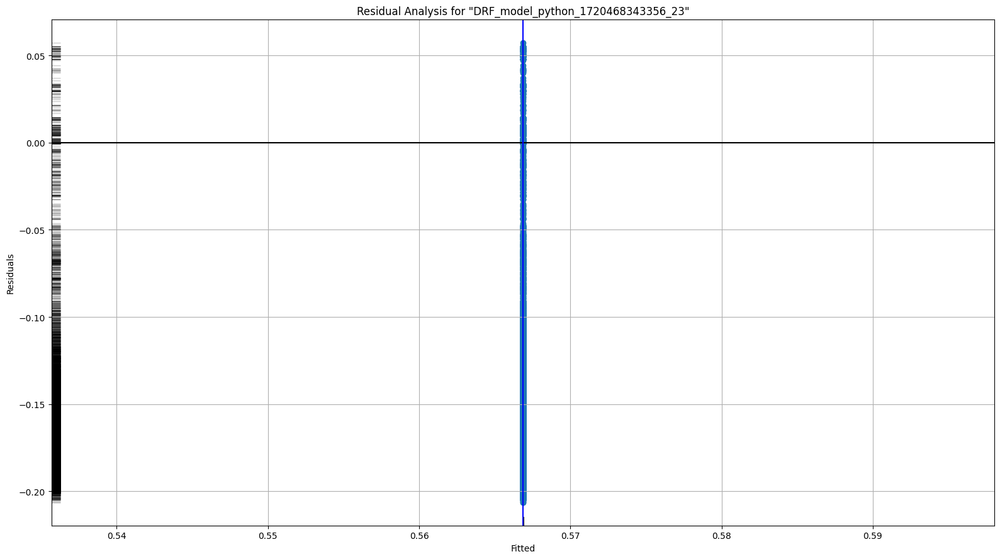

# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

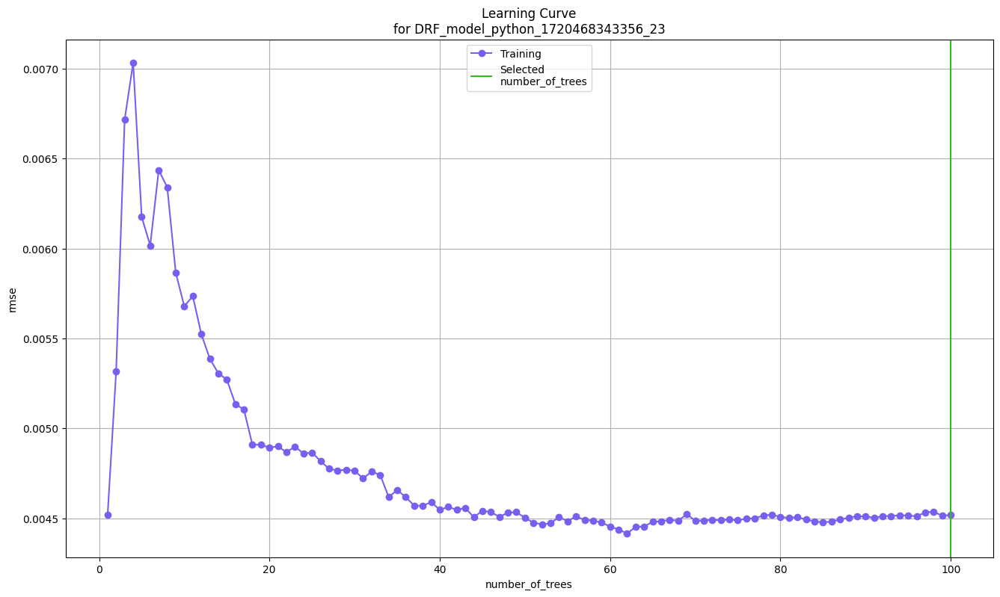

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

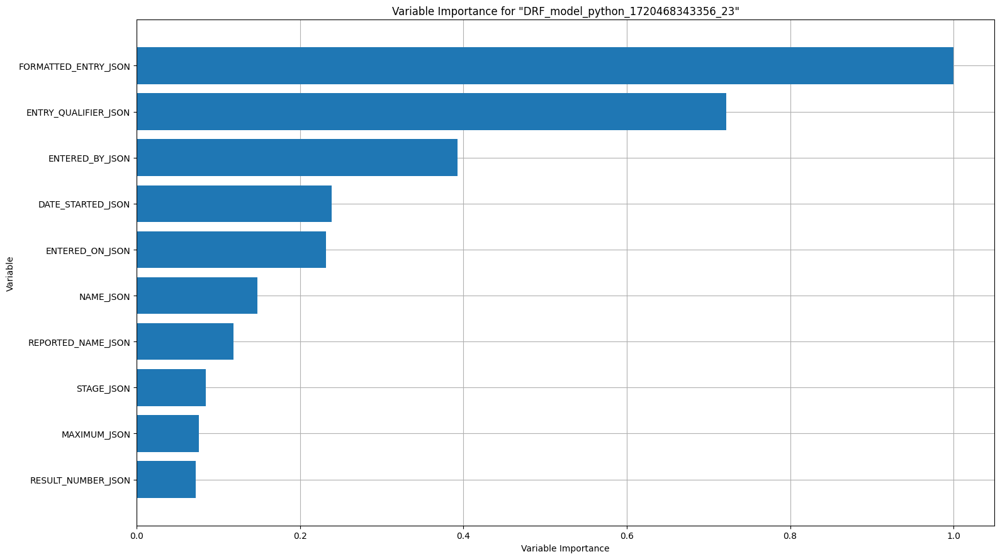

H2OValueError: Column ''FORMATTED_ENTRY_JSON'' does not exist in the frame

In [9]:
# single row explain
shapr_plot = DRF_model.shap_explain_row_plot(finalH2oFrame, row_index=0)

In [ ]:
mlflow.end_run()